In [ ]:

# STEP 1: Import libraries and load data

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

df = pd.read_csv("/content/train.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Shape: (1253, 592)


,timestamp,target,sensor_0,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,...,sensor_580,sensor_581,sensor_582,sensor_583,sensor_584,sensor_585,sensor_586,sensor_587,sensor_588,sensor_589
0,24/08/2008 07:14:00,0,2882.17,2601.98,2213.9333,1248.6209,1.8848,100.0,97.1856,0.1209,...,NaN,NaN,0.5090,0.0168,0.0048,3.2968,0.0282,0.0194,0.0059,68.7444
1,06/10/2008 15:00:00,1,2988.39,2493.72,2206.4000,982.5452,1.1853,100.0,116.8167,0.1228,...,0.0039,0.0000,0.4972,0.0154,0.0035,3.0992,-0.0006,0.0118,0.0039,0.0000
2,17/10/2008 05:26:00,0,2978.81,2379.78,2206.3000,1110.4967,0.8236,100.0,99.4122,0.1208,...,0.0025,43.5231,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231
3,18/08/2008 17:16:00,0,3038.25,2337.96,2244.1111,1676.7316,0.9197,100.0,100.8067,0.1204,...,NaN,NaN,0.5033,0.0157,0.0042,3.1246,0.0274,0.0142,0.0046,51.9067
4,07/10/2008 19:24:00,0,2985.78,2460.97,2200.2111,1048.3108,1.6485,100.0,98.3222,0.1214,...,NaN,NaN,0.4963,0.0138,0.0040,2.7888,0.0458,0.0277,0.0100,60.5430


In [ ]:

# STEP 2: Basic dataset audit

print("Column names:")
print(df.columns.tolist()[:10], "...")

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts(dropna=False))

print("\nTarget percentages:")
print((df["target"].value_counts(normalize=True) * 100).round(2))


Column names:
['timestamp', 'target', 'sensor_0', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7'] ...

Missing values: 33940
Duplicate rows: 0

Target distribution:
target
0    1170
1      83
Name: count, dtype: int64

Target percentages:
target
0    93.38
1     6.62
Name: proportion, dtype: float64


In [ ]:

# STEP 3: Check dataset structure and quality

print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nMissing values in target:")
print(df["target"].isnull().sum())

sensor_cols = [c for c in df.columns if c.startswith("sensor_")]

print("\nNumber of sensor columns:", len(sensor_cols))

missing_pct = df[sensor_cols].isnull().mean() * 100
constant_count = sum(df[c].nunique(dropna=True) <= 1 for c in sensor_cols)

print("Sensors with >50% missing:", (missing_pct > 50).sum())
print("Constant sensors:", constant_count)

display(missing_pct.describe())


Dataset shape: (1253, 592)

Target distribution:
target
0    1170
1      83
Name: count, dtype: int64

Missing values in target:
0

Number of sensor columns: 590
Sensors with >50% missing: 24
Constant sensors: 116


,0
count,590.000000
mean,4.591015
std,15.523201
min,0.000000
25%,0.159617
50%,0.319234
75%,0.718276
max,90.822027


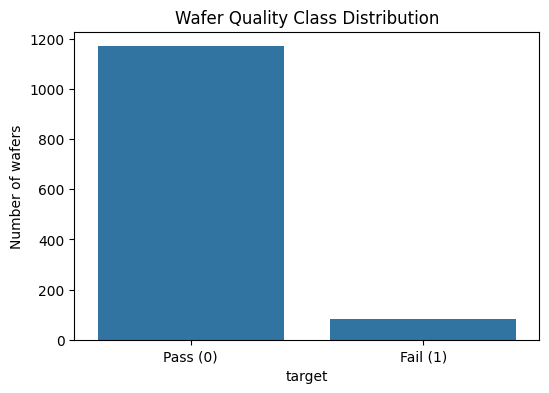

Pass wafers: 1170
Fail wafers: 83
Failure rate: 6.62 %


In [ ]:

# STEP 4: Class balance

target_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
sns.barplot(x=target_counts.index, y=target_counts.values)
plt.xticks([0, 1], ["Pass (0)", "Fail (1)"])
plt.ylabel("Number of wafers")
plt.title("Wafer Quality Class Distribution")
plt.show()

print("Pass wafers:", target_counts.get(0, 0))
print("Fail wafers:", target_counts.get(1, 0))
print("Failure rate:", round((df["target"] == 1).mean() * 100, 2), "%")


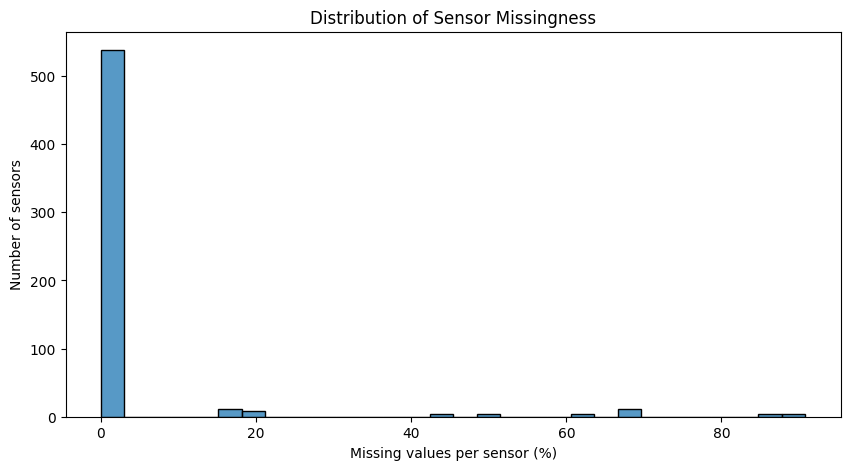

Sensors with >50% missing: 24
Sensors with no missing values: 84
Maximum missing percentage: 90.82 %


In [ ]:

# STEP 5: Missing values per sensor

missing_pct = df[sensor_cols].isnull().mean() * 100

plt.figure(figsize=(10, 5))
sns.histplot(missing_pct, bins=30)
plt.xlabel("Missing values per sensor (%)")
plt.ylabel("Number of sensors")
plt.title("Distribution of Sensor Missingness")
plt.show()

print("Sensors with >50% missing:", (missing_pct > 50).sum())
print("Sensors with no missing values:", (missing_pct == 0).sum())
print("Maximum missing percentage:", round(missing_pct.max(), 2), "%")


Invalid timestamps: 0


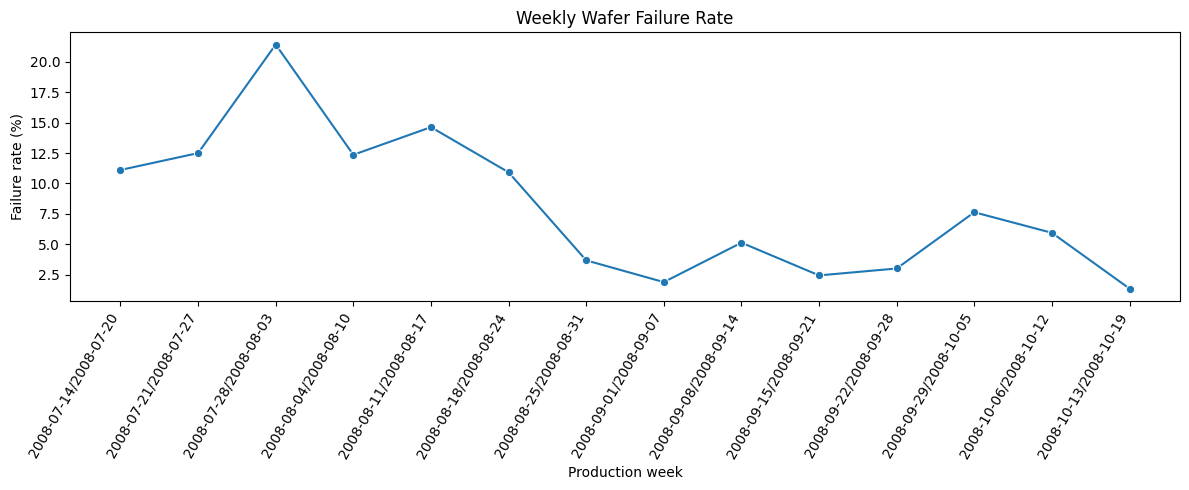

,week,wafers,failures,failure_rate_pct
0,2008-07-14/2008-07-20,9,1,11.111111
1,2008-07-21/2008-07-27,16,2,12.500000
2,2008-07-28/2008-08-03,42,9,21.428571
3,2008-08-04/2008-08-10,89,11,12.359551
4,2008-08-11/2008-08-17,41,6,14.634146
5,2008-08-18/2008-08-24,174,19,10.919540
6,2008-08-25/2008-08-31,136,5,3.676471
7,2008-09-01/2008-09-07,106,2,1.886792
8,2008-09-08/2008-09-14,78,4,5.128205
9,2008-09-15/2008-09-21,123,3,2.439024


In [ ]:

# STEP 6: Failure rate over time

df["timestamp"] = pd.to_datetime(
    df["timestamp"], dayfirst=True, errors="coerce"
)

print("Invalid timestamps:", df["timestamp"].isna().sum())

time_df = df.dropna(subset=["timestamp"]).copy()
time_df["week"] = time_df["timestamp"].dt.to_period("W").astype(str)

weekly = time_df.groupby("week")["target"].agg(
    wafers="count",
    failures="sum",
    failure_rate="mean"
).reset_index()

weekly["failure_rate_pct"] = weekly["failure_rate"] * 100

plt.figure(figsize=(12, 5))
sns.lineplot(data=weekly, x="week", y="failure_rate_pct", marker="o")
plt.xticks(rotation=60, ha="right")
plt.ylabel("Failure rate (%)")
plt.xlabel("Production week")
plt.title("Weekly Wafer Failure Rate")
plt.tight_layout()
plt.show()

display(weekly[["week", "wafers", "failures", "failure_rate_pct"]])


Number of constant sensors: 116
Examples: ['sensor_5', 'sensor_13', 'sensor_42', 'sensor_49', 'sensor_52', 'sensor_69', 'sensor_97', 'sensor_141', 'sensor_149', 'sensor_178', 'sensor_179', 'sensor_186', 'sensor_189', 'sensor_190', 'sensor_191', 'sensor_192', 'sensor_193', 'sensor_194', 'sensor_226', 'sensor_229']


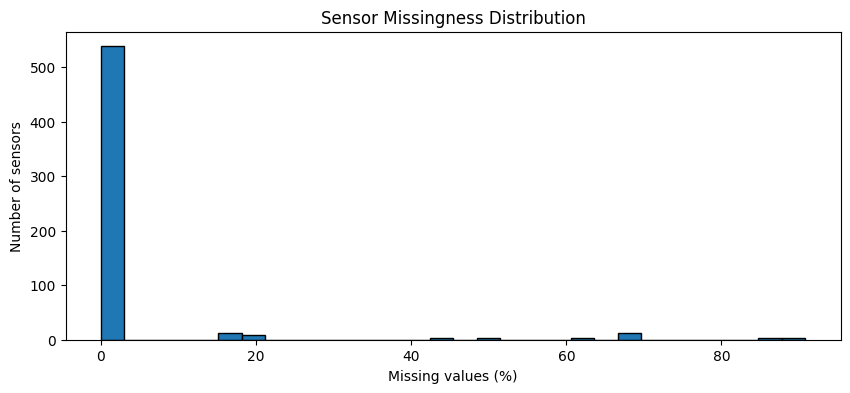

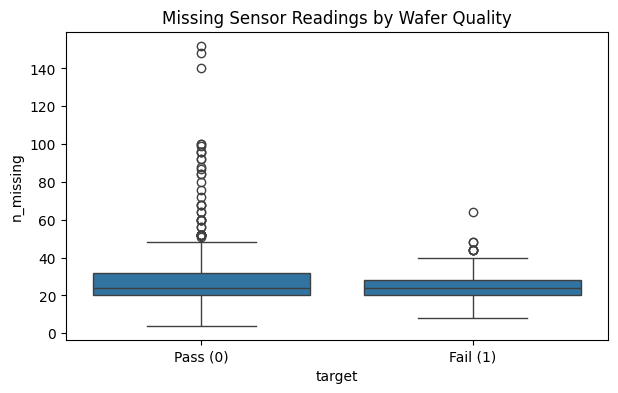

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
0,1170.0,27.179487,14.039548,4.0,20.0,24.0,32.0,152.0
1,83.0,25.783133,10.116454,8.0,20.0,24.0,28.0,64.0


In [ ]:

# STEP 7: Constant sensor analysis

constant_sensors = [
    c for c in sensor_cols
    if df[c].nunique(dropna=True) <= 1
]

print("Number of constant sensors:", len(constant_sensors))
print("Examples:", constant_sensors[:20])

# Plot sensor missingness
plt.figure(figsize=(10, 4))
plt.hist(missing_pct, bins=30, edgecolor="black")
plt.xlabel("Missing values (%)")
plt.ylabel("Number of sensors")
plt.title("Sensor Missingness Distribution")
plt.show()

# Count missing readings per wafer
df["n_missing"] = df[sensor_cols].isnull().sum(axis=1)

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="target", y="n_missing")
plt.xticks([0, 1], ["Pass (0)", "Fail (1)"])
plt.title("Missing Sensor Readings by Wafer Quality")
plt.show()

display(df.groupby("target")["n_missing"].describe())


Top 20 sensors by individual signal:


,sensor,auc,signal_strength,valid_rows
0,sensor_111,0.280647,0.719353,418
1,sensor_59,0.704271,0.704271,1248
2,sensor_247,0.671500,0.671500,690
3,sensor_519,0.670477,0.670477,690
4,sensor_103,0.667205,0.667205,1251
5,sensor_85,0.341176,0.658824,177
6,sensor_293,0.640673,0.640673,115
7,sensor_510,0.640199,0.640199,1251
8,sensor_385,0.635926,0.635926,690
9,sensor_28,0.364357,0.635643,1251


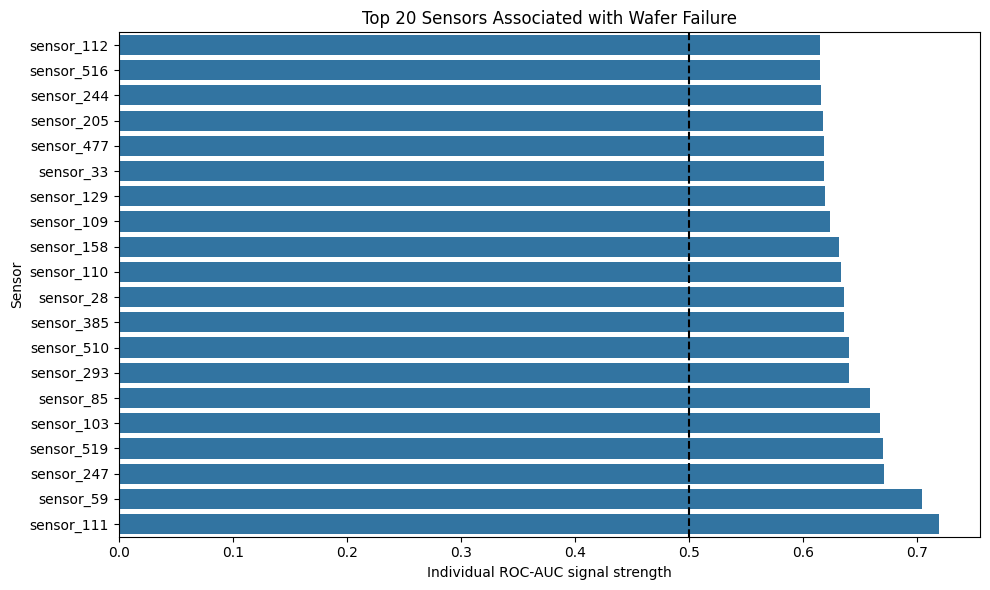

In [ ]:

from sklearn.metrics import roc_auc_score

# STEP 8: Rank sensors by individual predictive signal

sensor_auc = []

for col in sensor_cols:
    valid = df[col].notna()

    # Skip sensors with insufficient variation
    if df.loc[valid, col].nunique() < 2:
        continue

    y_valid = df.loc[valid, "target"]
    x_valid = df.loc[valid, col]

    # Both classes must be present
    if y_valid.nunique() < 2:
        continue

    auc = roc_auc_score(y_valid, x_valid)

    # AUC below 0.5 can indicate a reverse relationship
    signal_auc = max(auc, 1 - auc)

    sensor_auc.append({
        "sensor": col,
        "auc": auc,
        "signal_strength": signal_auc,
        "valid_rows": int(valid.sum())
    })

auc_df = pd.DataFrame(sensor_auc)
auc_df = auc_df.sort_values(
    "signal_strength", ascending=False
).reset_index(drop=True)

print("Top 20 sensors by individual signal:")
display(auc_df.head(20))

plt.figure(figsize=(10, 6))
top20 = auc_df.head(20).sort_values("signal_strength")
sns.barplot(
    data=top20,
    x="signal_strength",
    y="sensor"
)
plt.axvline(0.5, linestyle="--", color="black")
plt.xlabel("Individual ROC-AUC signal strength")
plt.ylabel("Sensor")
plt.title("Top 20 Sensors Associated with Wafer Failure")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 9: Prepare features and target

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, average_precision_score

RANDOM_STATE = 42

# Sensor-only baseline; target is kept separate
sensor_cols = [
    c for c in df.columns if c.startswith("sensor_")
]

X = df[sensor_cols].copy()
y = df["target"].astype(int).copy()

# Split before fitting preprocessing
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# All learned preprocessing happens inside the pipeline
baseline_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=RANDOM_STATE
    ))
])

baseline_pipe.fit(X_train, y_train)

# Evaluate on the untouched validation split
pred = baseline_pipe.predict(X_valid)
proba = baseline_pipe.predict_proba(X_valid)[:, 1]

print("Baseline model evaluation")
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_valid, pred), 4))
print("PR-AUC (average precision):",
      round(average_precision_score(y_valid, proba), 4))
print("Original sensor count:", X.shape[1])
print("Sensors after variance filtering:",
      baseline_pipe.named_steps["variance"].get_support().sum())


Baseline model evaluation
Balanced accuracy: 0.5792
PR-AUC (average precision): 0.2004
Original sensor count: 590
Sensors after variance filtering: 474


In [ ]:

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import balanced_accuracy_score, average_precision_score

# STEP 10: Extra Trees model

extra_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", ExtraTreesClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        class_weight="balanced",
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

extra_pipe.fit(X_train, y_train)

extra_pred = extra_pipe.predict(X_valid)
extra_proba = extra_pipe.predict_proba(X_valid)[:, 1]

print("Extra Trees evaluation")
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_valid, extra_pred), 4))
print("PR-AUC (average precision):",
      round(average_precision_score(y_valid, extra_proba), 4))


Extra Trees evaluation
Balanced accuracy: 0.4979
PR-AUC (average precision): 0.1479


In [ ]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.metrics import balanced_accuracy_score, average_precision_score

# STEP 11: Gradient boosting model

boost_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold(threshold=0.0)),
    ("model", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=8,
        l2_regularization=5.0,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

boost_pipe.fit(X_train, y_train)

boost_pred = boost_pipe.predict(X_valid)
boost_proba = boost_pipe.predict_proba(X_valid)[:, 1]

print("Gradient Boosting evaluation")
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_valid, boost_pred), 4))
print("PR-AUC (average precision):",
      round(average_precision_score(y_valid, boost_proba), 4))


Gradient Boosting evaluation
Balanced accuracy: 0.523
PR-AUC (average precision): 0.1668


In [ ]:

from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

# STEP 12: Reliable baseline evaluation

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=RANDOM_STATE
)

scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "pr_auc": "average_precision"
}

cv_results = cross_validate(
    baseline_pipe,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False
)

print("Logistic Regression — Repeated 5-fold CV")
print(
    "Balanced accuracy: "
    f"{cv_results['test_balanced_accuracy'].mean():.4f} "
    f"+/- {cv_results['test_balanced_accuracy'].std():.4f}"
)
print(
    "PR-AUC: "
    f"{cv_results['test_pr_auc'].mean():.4f} "
    f"+/- {cv_results['test_pr_auc'].std():.4f}"
)


Logistic Regression — Repeated 5-fold CV
Balanced accuracy: 0.5729 +/- 0.0461
PR-AUC: 0.1390 +/- 0.0359


In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

models = {
    "Logistic Regression": baseline_pipe,
    "Extra Trees": extra_pipe,
    "HistGradientBoosting": boost_pipe
}

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=RANDOM_STATE
)

scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "pr_auc": "average_precision"
}

for name, model in models.items():
    results = cross_validate(
        model, X, y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    print(f"\n{name}")
    print(f"Balanced Accuracy: "
          f"{results['test_balanced_accuracy'].mean():.4f}")
    print(f"PR-AUC: {results['test_pr_auc'].mean():.4f}")


Logistic Regression
Balanced Accuracy: 0.5729
PR-AUC: 0.1390

Extra Trees
Balanced Accuracy: 0.5006
PR-AUC: 0.2013

HistGradientBoosting
Balanced Accuracy: 0.5374
PR-AUC: 0.2109


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

boost_configs = {
    "Boost A": HistGradientBoostingClassifier(
        learning_rate=0.03, max_iter=300,
        max_leaf_nodes=7, l2_regularization=10.0,
        class_weight="balanced", random_state=42
    ),
    "Boost B": HistGradientBoostingClassifier(
        learning_rate=0.05, max_iter=300,
        max_leaf_nodes=15, l2_regularization=5.0,
        class_weight="balanced", random_state=42
    ),
    "Boost C": HistGradientBoostingClassifier(
        learning_rate=0.03, max_iter=200,
        max_leaf_nodes=15, l2_regularization=20.0,
        class_weight="balanced", random_state=42
    )
}

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=42
)

for name, model in boost_configs.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("model", model)
    ])

    scores = cross_validate(
        pipe, X, y, cv=cv,
        scoring={
            "balanced_accuracy": "balanced_accuracy",
            "pr_auc": "average_precision"
        },
        n_jobs=-1
    )

    print(
        f"{name} | "
        f"Balanced Accuracy: {scores['test_balanced_accuracy'].mean():.4f} | "
        f"PR-AUC: {scores['test_pr_auc'].mean():.4f}"
    )

Boost A | Balanced Accuracy: 0.5467 | PR-AUC: 0.2051
Boost B | Balanced Accuracy: 0.5171 | PR-AUC: 0.2065
Boost C | Balanced Accuracy: 0.5452 | PR-AUC: 0.2036


In [ ]:
import numpy as np
from sklearn.metrics import balanced_accuracy_score, average_precision_score

# Fit the original HistGradientBoosting model
boost_pipe.fit(X_train, y_train)

valid_proba = boost_pipe.predict_proba(X_valid)[:, 1]

print("PR-AUC:", round(average_precision_score(y_valid, valid_proba), 4))
print("\nThreshold | Balanced Accuracy")

for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (valid_proba >= threshold).astype(int)
    score = balanced_accuracy_score(y_valid, predictions)
    print(f"{threshold:.2f}      | {score:.4f}")

PR-AUC: 0.1668

Threshold | Balanced Accuracy
0.10      | 0.6263
0.15      | 0.5616
0.20      | 0.5578
0.25      | 0.5455
0.30      | 0.5562
0.35      | 0.5711
0.40      | 0.5733
0.45      | 0.5776
0.50      | 0.5230
0.55      | 0.5230
0.60      | 0.5251
0.65      | 0.4957
0.70      | 0.4957
0.75      | 0.4957
0.80      | 0.4957
0.85      | 0.5000
0.90      | 0.5000


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

threshold = 0.45

valid_pred = (valid_proba >= threshold).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_valid, valid_pred))

print("\nClassification Report:")
print(classification_report(
    y_valid,
    valid_pred,
    target_names=["Pass (0)", "Fail (1)"],
    zero_division=0
))

Confusion Matrix:
[[229   5]
 [ 14   3]]

Classification Report:
              precision    recall  f1-score   support

    Pass (0)       0.94      0.98      0.96       234
    Fail (1)       0.38      0.18      0.24        17

    accuracy                           0.92       251
   macro avg       0.66      0.58      0.60       251
weighted avg       0.90      0.92      0.91       251



In [ ]:
from sklearn.metrics import balanced_accuracy_score, precision_score, recall_score

print("Threshold | Balanced Acc | Fail Precision | Fail Recall")

for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45]:
    pred = (valid_proba >= threshold).astype(int)

    print(
        f"{threshold:.2f}      | "
        f"{balanced_accuracy_score(y_valid, pred):.4f}        | "
        f"{precision_score(y_valid, pred, zero_division=0):.4f}         | "
        f"{recall_score(y_valid, pred, zero_division=0):.4f}"
    )

Threshold | Balanced Acc | Fail Precision | Fail Recall
0.05      | 0.6900        | 0.1262         | 0.7647
0.10      | 0.6263        | 0.1356         | 0.4706
0.15      | 0.5616        | 0.1111         | 0.2941
0.20      | 0.5578        | 0.1250         | 0.2353
0.25      | 0.5455        | 0.1304         | 0.1765
0.30      | 0.5562        | 0.1667         | 0.1765
0.35      | 0.5711        | 0.2727         | 0.1765
0.40      | 0.5733        | 0.3000         | 0.1765
0.45      | 0.5776        | 0.3750         | 0.1765


In [ ]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_predict
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    average_precision_score
)

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=42
)

oof_proba = cross_val_predict(
    boost_pipe, X, y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold PR-AUC:", round(
    average_precision_score(y, oof_proba), 4
))
print("\nThreshold | Balanced Acc | Fail Precision | Fail Recall")

for t in [0.03, 0.05, 0.07, 0.10, 0.15, 0.20]:
    pred = (oof_proba >= t).astype(int)
    print(
        f"{t:.2f}      | "
        f"{balanced_accuracy_score(y, pred):.4f}        | "
        f"{precision_score(y, pred, zero_division=0):.4f}         | "
        f"{recall_score(y, pred, zero_division=0):.4f}"
    )

ValueError: cross_val_predict only works for partitions

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score

cv_once = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

oof_proba = cross_val_predict(
    boost_pipe, X, y,
    cv=cv_once,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold PR-AUC:",
      round(average_precision_score(y, oof_proba), 4))

for t in [0.03, 0.05, 0.07, 0.10, 0.15, 0.20]:
    pred = (oof_proba >= t).astype(int)
    print(
        f"Threshold={t:.2f} | "
        f"Balanced accuracy={balanced_accuracy_score(y, pred):.4f} | "
        f"Fail precision={precision_score(y, pred, zero_division=0):.4f} | "
        f"Fail recall={recall_score(y, pred, zero_division=0):.4f}"
    )

Out-of-fold PR-AUC: 0.2016
Threshold=0.03 | Balanced accuracy=0.6087 | Fail precision=0.0894 | Fail recall=0.7831
Threshold=0.05 | Balanced accuracy=0.6318 | Fail precision=0.1043 | Fail recall=0.6747
Threshold=0.07 | Balanced accuracy=0.6254 | Fail precision=0.1130 | Fail recall=0.5663
Threshold=0.10 | Balanced accuracy=0.6337 | Fail precision=0.1340 | Fail recall=0.4940
Threshold=0.15 | Balanced accuracy=0.6274 | Fail precision=0.1650 | Fail recall=0.3976
Threshold=0.20 | Balanced accuracy=0.6131 | Fail precision=0.1888 | Fail recall=0.3253


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate, RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import HistGradientBoostingClassifier

# Sensor data only
X_sensor = df[sensor_cols].copy()

# Sensor data plus number of missing readings
X_missing = X_sensor.copy()
X_missing["n_missing"] = X_sensor.isnull().sum(axis=1)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("classifier", HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=200,
        max_leaf_nodes=8,
        l2_regularization=5.0,
        class_weight="balanced",
        random_state=42
    ))
])

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=42
)

scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "pr_auc": "average_precision"
}

for name, features in [
    ("Sensors only", X_sensor),
    ("Sensors + missing count", X_missing)
]:
    scores = cross_validate(
        model, features, y,
        cv=cv, scoring=scoring, n_jobs=-1
    )

    print(f"\n{name}")
    print(f"Balanced accuracy: "
          f"{scores['test_balanced_accuracy'].mean():.4f}")
    print(f"PR-AUC: {scores['test_pr_auc'].mean():.4f}")


Sensors only
Balanced accuracy: 0.5374
PR-AUC: 0.2109

Sensors + missing count
Balanced accuracy: 0.5370
PR-AUC: 0.2116


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

weight_options = {
    "Balanced": "balanced",
    "No class weighting": None
}

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=42
)

for name, weight in weight_options.items():
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("classifier", HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=8,
            l2_regularization=5.0,
            class_weight=weight,
            random_state=42
        ))
    ])

    scores = cross_validate(
        model, X, y,
        cv=cv,
        scoring={
            "balanced_accuracy": "balanced_accuracy",
            "pr_auc": "average_precision"
        },
        n_jobs=-1
    )

    print(f"\n{name}")
    print(f"Balanced accuracy: "
          f"{scores['test_balanced_accuracy'].mean():.4f}")
    print(f"PR-AUC: {scores['test_pr_auc'].mean():.4f}")


Balanced
Balanced accuracy: 0.5374
PR-AUC: 0.2109

No class weighting
Balanced accuracy: 0.5007
PR-AUC: 0.2004


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

rf_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("model", RandomForestClassifier(
        n_estimators=400,
        min_samples_leaf=3,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=1
    ))
])

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=42
)

scores = cross_validate(
    rf_pipe, X, y,
    cv=cv,
    scoring={
        "balanced_accuracy": "balanced_accuracy",
        "pr_auc": "average_precision"
    },
    n_jobs=-1
)

print("Random Forest")
print(f"Balanced accuracy: "
      f"{scores['test_balanced_accuracy'].mean():.4f}")
print(f"PR-AUC: {scores['test_pr_auc'].mean():.4f}")

Random Forest
Balanced accuracy: 0.5000
PR-AUC: 0.2181


In [ ]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

et_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("model", ExtraTreesClassifier(
        n_estimators=500,
        min_samples_leaf=2,
        max_features=0.5,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=1
    ))
])

cv = RepeatedStratifiedKFold(
    n_splits=5, n_repeats=5, random_state=42
)

scores = cross_validate(
    et_pipe, X, y,
    cv=cv,
    scoring={
        "balanced_accuracy": "balanced_accuracy",
        "pr_auc": "average_precision"
    },
    n_jobs=-1
)

print("Extra Trees (tuned)")
print(f"Balanced accuracy: "
      f"{scores['test_balanced_accuracy'].mean():.4f}")
print(f"PR-AUC: {scores['test_pr_auc'].mean():.4f}")

Extra Trees (tuned)
Balanced accuracy: 0.5000
PR-AUC: 0.1873


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    precision_score,
    recall_score
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

rf_pipe.fit(X_train, y_train)

rf_proba = rf_pipe.predict_proba(X_valid)[:, 1]

print("PR-AUC:", round(
    average_precision_score(y_valid, rf_proba), 4
))
print("\nThreshold | Balanced Acc | Fail Precision | Fail Recall")

for t in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50]:
    pred = (rf_proba >= t).astype(int)

    print(
        f"{t:.2f} | "
        f"{balanced_accuracy_score(y_valid, pred):.4f} | "
        f"{precision_score(y_valid, pred, zero_division=0):.4f} | "
        f"{recall_score(y_valid, pred, zero_division=0):.4f}"
    )

PR-AUC: 0.1397

Threshold | Balanced Acc | Fail Precision | Fail Recall
0.05 | 0.5860 | 0.0816 | 0.9412
0.10 | 0.6953 | 0.1549 | 0.6471
0.15 | 0.6060 | 0.1538 | 0.3529
0.20 | 0.4974 | 0.0625 | 0.0588
0.25 | 0.5209 | 0.2000 | 0.0588
0.30 | 0.4979 | 0.0000 | 0.0000
0.35 | 0.5000 | 0.0000 | 0.0000
0.40 | 0.5000 | 0.0000 | 0.0000
0.50 | 0.5000 | 0.0000 | 0.0000


In [ ]:
with open(
    "/content/secom_sensor_metadata.names",
    "r",
    encoding="utf-8",
    errors="ignore"
) as f:
    for line in f.readlines()[:40]:
        print(line.rstrip())

Title: SECOM Data Set

Abstract: Data from a semi-conductor manufacturing process


-----------------------------------------------------

Data Set Characteristics: Multivariate
Number of Instances: 1567
Area: Computer
Attribute Characteristics: Real
Number of Attributes: 591
Date Donated: 2008-11-19
Associated Tasks: Classification, Causal-Discovery
Missing Values? Yes

-----------------------------------------------------

Source:

Authors: Michael McCann, Adrian Johnston

-----------------------------------------------------

Data Set Information:

A complex modern semi-conductor manufacturing process is normally under consistent
surveillance via the monitoring of signals/variables collected from sensors and or
process measurement points. However, not all of these signals are equally valuable
in a specific monitoring system. The measured signals contain a combination of
useful information, irrelevant information as well as noise. It is often the case
that useful information is burie

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

final_candidates = {
    "Random Forest": rf_pipe,
    "HistGradientBoosting": boost_pipe
}

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

scoring = {
    "balanced_accuracy": "balanced_accuracy",
    "pr_auc": "average_precision"
}

for name, model in final_candidates.items():
    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    print(f"\n{name}")
    print(
        f"Balanced accuracy: "
        f"{results['test_balanced_accuracy'].mean():.4f} "
        f"+/- {results['test_balanced_accuracy'].std():.4f}"
    )
    print(
        f"PR-AUC: "
        f"{results['test_pr_auc'].mean():.4f} "
        f"+/- {results['test_pr_auc'].std():.4f}"
    )


Random Forest
Balanced accuracy: 0.5000 +/- 0.0000
PR-AUC: 0.2181 +/- 0.0664

HistGradientBoosting
Balanced accuracy: 0.5374 +/- 0.0447
PR-AUC: 0.2109 +/- 0.0824


In [ ]:
import joblib

final_model = boost_pipe
final_model.fit(X, y)

joblib.dump(
    {
        "model": final_model,
        "sensor_columns": sensor_cols,
        "threshold": 0.10
    },
    "/content/waferguard_model.joblib"
)

print("Model trained and saved successfully.")
print("Training rows:", len(X))
print("Sensor features:", len(sensor_cols))
print("Decision threshold:", 0.10)

Model trained and saved successfully.
Training rows: 1253
Sensor features: 590
Decision threshold: 0.1


In [ ]:
import joblib
import pandas as pd

artifact = joblib.load("/content/waferguard_model.joblib")

model = artifact["model"]
sensor_columns = artifact["sensor_columns"]
threshold = artifact["threshold"]

# Test on 5 rows from the available dataset
sample = df[sensor_columns].head(5)

probabilities = model.predict_proba(sample)[:, 1]
predictions = (probabilities >= threshold).astype(int)

results = pd.DataFrame({
    "Failure_Probability": probabilities.round(4),
    "Prediction": [
        "FAIL" if p == 1 else "PASS"
        for p in predictions
    ]
})

print(results)

   Failure_Probability Prediction
0               0.0858       PASS
1               0.9401       FAIL
2               0.0118       PASS
3               0.0971       PASS
4               0.0060       PASS


In [ ]:
from google.colab import files
files.download("/content/waferguard_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile /content/inference.py

import joblib
import pandas as pd

MODEL_PATH = "/content/waferguard_model.joblib"


def predict_wafers(input_df, model_path=MODEL_PATH):
    artifact = joblib.load(model_path)

    model = artifact["model"]
    sensor_columns = artifact["sensor_columns"]
    threshold = artifact["threshold"]

    missing = [c for c in sensor_columns if c not in input_df.columns]
    if missing:
        raise ValueError(
            f"Input is missing {len(missing)} required sensor columns."
        )

    # Keep sensor columns in the exact training order
    X_new = input_df[sensor_columns].copy()

    probabilities = model.predict_proba(X_new)[:, 1]
    predictions = (probabilities >= threshold).astype(int)

    return pd.DataFrame({
        "failure_probability": probabilities,
        "prediction": ["FAIL" if p == 1 else "PASS" for p in predictions]
    })

Writing /content/inference.py


In [ ]:
from inference import predict_wafers

sample_results = predict_wafers(df[sensor_cols].head(5))
print(sample_results.round(4))

   failure_probability prediction
0               0.0858       PASS
1               0.9401       FAIL
2               0.0118       PASS
3               0.0971       PASS
4               0.0060       PASS


In [ ]:
import pandas as pd

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Balanced Accuracy": "0.5729 ± 0.0461",
        "PR-AUC": "0.1390 ± 0.0359"
    },
    {
        "Model": "HistGradientBoosting",
        "Balanced Accuracy": "0.5374 ± 0.0447",
        "PR-AUC": "0.2109 ± 0.0824"
    },
    {
        "Model": "Random Forest",
        "Balanced Accuracy": "0.5000 ± 0.0000",
        "PR-AUC": "0.2181 ± 0.0664"
    },
    {
        "Model": "Extra Trees (tuned)",
        "Balanced Accuracy": "0.5000",
        "PR-AUC": "0.1873"
    }
])

print("WAFERGUARD AI — MODEL COMPARISON")
print(results.to_string(index=False))

print("\nDataset:")
print("Wafers:", len(df))
print("Sensor features:", len(sensor_cols))
print("Passing wafers:", int((y == 0).sum()))
print("Failing wafers:", int((y == 1).sum()))

WAFERGUARD AI — MODEL COMPARISON
               Model Balanced Accuracy          PR-AUC
 Logistic Regression   0.5729 ± 0.0461 0.1390 ± 0.0359
HistGradientBoosting   0.5374 ± 0.0447 0.2109 ± 0.0824
       Random Forest   0.5000 ± 0.0000 0.2181 ± 0.0664
 Extra Trees (tuned)            0.5000          0.1873

Dataset:
Wafers: 1253
Sensor features: 590
Passing wafers: 1170
Failing wafers: 83


In [ ]:
%%writefile /content/app.py

import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="WaferGuard AI",
    page_icon="🔬",
    layout="wide"
)

@st.cache_resource
def load_model():
    return joblib.load("waferguard_model.joblib")

st.title("🔬 WaferGuard AI")
st.subheader("Semiconductor Wafer Fault Detection")
st.write(
    "Upload wafer sensor readings to estimate failure probability "
    "and identify wafers that may need inspection."
)

try:
    artifact = load_model()
    model = artifact["model"]
    sensor_columns = artifact["sensor_columns"]
    threshold = artifact["threshold"]

    st.success("Model loaded successfully.")

    uploaded_file = st.file_uploader(
        "Upload a CSV containing wafer sensor readings",
        type=["csv"]
    )

    if uploaded_file is not None:
        data = pd.read_csv(uploaded_file)

        missing = [
            col for col in sensor_columns
            if col not in data.columns
        ]

        if missing:
            st.error(
                f"CSV is missing {len(missing)} required sensor columns."
            )
        else:
            X_new = data[sensor_columns]
            probabilities = model.predict_proba(X_new)[:, 1]
            predictions = probabilities >= threshold

            results = pd.DataFrame({
                "Failure Probability (%)": (
                    probabilities * 100
                ).round(2),
                "Prediction": [
                    "FAIL" if p else "PASS"
                    for p in predictions
                ]
            })

            st.metric("Wafers analyzed", len(results))
            st.metric("Flagged for inspection", int(predictions.sum()))

            st.dataframe(results, use_container_width=True)

            st.download_button(
                "Download predictions",
                results.to_csv(index=False).encode("utf-8"),
                file_name="waferguard_predictions.csv",
                mime="text/csv"
            )

except Exception as e:
    st.error(f"Could not load the model: {e}")
    st.info(
        "Ensure waferguard_model.joblib is in the same folder as app.py."
    )

Writing /content/app.py


In [ ]:
!pip -q install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 58.6 MB/s eta 0:00:00


In [ ]:
!ls -lh /content/waferguard_model.joblib /content/app.py

-rw-r--r-- 1 root root 2.2K Oct 18 19:21 /content/app.py
-rw-r--r-- 1 root root 1.1M Oct 18 19:11 /content/waferguard_model.joblib


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!sleep 3
!cat /content/streamlit.log



2026-10-18 19:25:11.829 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://35.231.128.183:8501



In [ ]:
!pip -q install pyngrok

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("38ZWLyIqJyyy3NiFrwlFZvc8A25_2j3kwYJdD3VyysrbfN6jg")
public_url = ngrok.connect(8501, "http")

print("Open WaferGuard AI here:", public_url)

Open WaferGuard AI here: NgrokTunnel: "https://unignited-emily-unbodied.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
import pandas as pd
from sklearn.metrics import (
    balanced_accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

# Sort wafers chronologically
ordered = df.sort_values("timestamp").reset_index(drop=True)

X_all = ordered[sensor_cols]
y_all = ordered["target"].astype(int)

# Earlier 80% for training; latest 20% for testing
split = int(len(ordered) * 0.80)

X_train_time = X_all.iloc[:split]
y_train_time = y_all.iloc[:split]

X_test_time = X_all.iloc[split:]
y_test_time = y_all.iloc[split:]

print("Training wafers:", len(X_train_time))
print("Later test wafers:", len(X_test_time))
print("Failures in later test set:", int(y_test_time.sum()))

# Fit only on earlier wafers
boost_pipe.fit(X_train_time, y_train_time)

# Predict the later wafers
probabilities = boost_pipe.predict_proba(X_test_time)[:, 1]
predictions = (probabilities >= 0.10).astype(int)

print("\nPR-AUC:", round(
    average_precision_score(y_test_time, probabilities), 4
))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_test_time, predictions), 4
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test_time, predictions, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_test_time,
    predictions,
    labels=[0, 1],
    target_names=["PASS", "FAIL"],
    zero_division=0
))

Training wafers: 1002
Later test wafers: 251
Failures in later test set: 14

PR-AUC: 0.065
Balanced accuracy: 0.4724

Confusion matrix:
[[207  30]
 [ 13   1]]

Classification report:
              precision    recall  f1-score   support

        PASS       0.94      0.87      0.91       237
        FAIL       0.03      0.07      0.04        14

    accuracy                           0.83       251
   macro avg       0.49      0.47      0.48       251
weighted avg       0.89      0.83      0.86       251



In [ ]:
import pandas as pd

ordered = df.sort_values("timestamp").reset_index(drop=True)
split = int(len(ordered) * 0.80)

train_period = ordered.iloc[:split].copy()
test_period = ordered.iloc[split:].copy()

print("TRAINING PERIOD")
print("Date range:",
      train_period["timestamp"].min(),
      "to",
      train_period["timestamp"].max())
print("Rows:", len(train_period))
print("Failures:", int(train_period["target"].sum()))
print("Failure rate:",
      round(train_period["target"].mean() * 100, 2), "%")

print("\nLATER TEST PERIOD")
print("Date range:",
      test_period["timestamp"].min(),
      "to",
      test_period["timestamp"].max())
print("Rows:", len(test_period))
print("Failures:", int(test_period["target"].sum()))
print("Failure rate:",
      round(test_period["target"].mean() * 100, 2), "%")

TRAINING PERIOD
Date range: 2008-07-19 11:55:00 to 2008-10-02 07:58:00
Rows: 1002
Failures: 69
Failure rate: 6.89 %

LATER TEST PERIOD
Date range: 2008-10-02 08:24:00 to 2008-10-17 06:07:00
Rows: 251
Failures: 14
Failure rate: 5.58 %


In [ ]:
import numpy as np
import pandas as pd

train_period = ordered.iloc[:split]
test_period = ordered.iloc[split:]

drift_rows = []

for col in sensor_cols:
    a = train_period[col].dropna()
    b = test_period[col].dropna()

    if len(a) < 20 or len(b) < 10:
        continue

    train_median = a.median()
    test_median = b.median()
    train_iqr = a.quantile(0.75) - a.quantile(0.25)
    test_iqr = b.quantile(0.75) - b.quantile(0.25)

    scale = train_iqr if train_iqr > 1e-12 else a.std()

    if pd.notna(scale) and scale > 1e-12:
        shift = abs(test_median - train_median) / scale
        drift_rows.append({
            "sensor": col,
            "median_shift_in_train_IQR": shift,
            "train_missing_pct": train_period[col].isna().mean() * 100,
            "test_missing_pct": test_period[col].isna().mean() * 100
        })

drift = pd.DataFrame(drift_rows).sort_values(
    "median_shift_in_train_IQR", ascending=False
)

print("Sensors compared:", len(drift))
print("\nTop 15 sensors with largest median shifts:")
print(drift.head(15).round(3).to_string(index=False))

print("\nMean missing percentage:")
print("Training:", round(train_period[sensor_cols].isna().mean().mean() * 100, 2), "%")
print("Later test:", round(test_period[sensor_cols].isna().mean().mean() * 100, 2), "%")

Sensors compared: 468

Top 15 sensors with largest median shifts:
    sensor  median_shift_in_train_IQR  train_missing_pct  test_missing_pct
sensor_543                     15.000              0.000             0.797
sensor_542                      2.643              0.000             0.797
sensor_544                      2.000              0.000             0.797
sensor_116                      2.000              0.000             0.000
sensor_111                      1.533             79.242            16.335
sensor_383                      1.434             79.242            16.335
sensor_517                      1.363             79.242            16.335
sensor_245                      1.251             79.242            16.335
sensor_545                      1.162              0.000             0.797
 sensor_95                      1.000              0.599             0.000
sensor_109                      0.971             79.242            16.335
 sensor_36                      0.

In [ ]:
inspect_sensors = [
    "sensor_543", "sensor_542", "sensor_544",
    "sensor_116", "sensor_111", "sensor_383"
]

for col in inspect_sensors:
    print(f"\n{'='*50}")
    print("Sensor:", col)

    for name, period in [
        ("Training period", train_period),
        ("Later period", test_period)
    ]:
        s = period[col]

        print(f"\n{name}")
        print("Missing (%):", round(s.isna().mean() * 100, 2))
        print("Median:", round(s.median(), 4))
        print("Mean:", round(s.mean(), 4))
        print("Std:", round(s.std(), 4))
        print("IQR:", round(
            s.quantile(0.75) - s.quantile(0.25), 4
        ))
        print("Unique values:", s.nunique())


Sensor: sensor_543

Training period
Missing (%): 0.0
Median: 0.0078
Mean: 0.0082
Std: 0.0014
IQR: 0.0001
Unique values: 60

Later period
Missing (%): 0.8
Median: 0.0093
Mean: 0.0093
Std: 0.0017
IQR: 0.0024
Unique values: 55

Sensor: sensor_542

Training period
Missing (%): 0.0
Median: 0.1096
Mean: 0.1108
Std: 0.0025
IQR: 0.0014
Unique values: 77

Later period
Missing (%): 0.8
Median: 0.1133
Mean: 0.1128
Std: 0.003
IQR: 0.0037
Unique values: 74

Sensor: sensor_544

Training period
Missing (%): 0.0
Median: 0.0026
Mean: 0.0025
Std: 0.0003
IQR: 0.0001
Unique values: 19

Later period
Missing (%): 0.8
Median: 0.0024
Mean: 0.0024
Std: 0.0004
IQR: 0.0005
Unique values: 18

Sensor: sensor_116

Training period
Missing (%): 0.0
Median: 0.9907
Mean: 0.987
Std: 0.0103
IQR: 0.0006
Unique values: 121

Later period
Missing (%): 0.0
Median: 0.9895
Mean: 0.9874
Std: 0.0072
IQR: 0.0008
Unique values: 50

Sensor: sensor_111

Training period
Missing (%): 79.24
Median: 230.8846
Mean: 230.9937
Std: 0.9445
I

In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    balanced_accuracy_score,
    average_precision_score,
    confusion_matrix
)

# Sensors identified during drift inspection
suspect_sensors = [
    "sensor_543", "sensor_542", "sensor_544",
    "sensor_116", "sensor_111", "sensor_383"
]

# Baseline: all sensors
model_all = clone(boost_pipe)
model_all.fit(X_train_time, y_train_time)

prob_all = model_all.predict_proba(X_test_time)[:, 1]
pred_all = (prob_all >= 0.10).astype(int)

# Experiment: exclude the six sensors
reduced_columns = [
    c for c in X_train_time.columns
    if c not in suspect_sensors
]

model_reduced = clone(boost_pipe)
model_reduced.fit(
    X_train_time[reduced_columns],
    y_train_time
)

prob_reduced = model_reduced.predict_proba(
    X_test_time[reduced_columns]
)[:, 1]

pred_reduced = (prob_reduced >= 0.10).astype(int)

# Compare
for name, probs, preds in [
    ("All sensors", prob_all, pred_all),
    ("Without six sensors", prob_reduced, pred_reduced)
]:
    print(f"\n{name}")
    print("Balanced accuracy:",
          round(balanced_accuracy_score(y_test_time, preds), 4))
    print("PR-AUC:",
          round(average_precision_score(y_test_time, probs), 4))
    print("Confusion matrix:")
    print(confusion_matrix(y_test_time, preds))


All sensors
Balanced accuracy: 0.4724
PR-AUC: 0.065
Confusion matrix:
[[207  30]
 [ 13   1]]

Without six sensors
Balanced accuracy: 0.4724
PR-AUC: 0.0701
Confusion matrix:
[[207  30]
 [ 13   1]]


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import average_precision_score, roc_auc_score

results = pd.DataFrame({
    "actual": y_test_time.to_numpy(),
    "probability": prob_all
})

print("Actual failures:", int((results["actual"] == 1).sum()))
print("Actual passes:", int((results["actual"] == 0).sum()))

print("\nProbability summary by actual class:")
print(
    results.groupby("actual")["probability"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

print("\nHighest-risk wafers:")
print(
    results.sort_values("probability", ascending=False)
    .head(20)
    .round(4)
    .to_string(index=False)
)

print("\nPR-AUC:", round(
    average_precision_score(results["actual"], results["probability"]), 4
))
print("ROC-AUC:", round(
    roc_auc_score(results["actual"], results["probability"]), 4
))

Actual failures: 14
Actual passes: 237

Probability summary by actual class:
        count    mean  median     min     max
actual                                       
0         237  0.0499  0.0301  0.0037  0.4180
1          14  0.0483  0.0327  0.0127  0.2348

Highest-risk wafers:
 actual  probability
      0       0.4180
      0       0.3067
      0       0.2893
      0       0.2886
      0       0.2668
      0       0.2596
      1       0.2348
      0       0.2301
      0       0.1862
      0       0.1838
      0       0.1633
      0       0.1496
      0       0.1474
      0       0.1470
      0       0.1417
      0       0.1396
      0       0.1310
      0       0.1303
      0       0.1263
      0       0.1258

PR-AUC: 0.065
ROC-AUC: 0.5093


In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import RobustScaler

# Logistic Regression pipeline
lr_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    ))
])

# Compare models on the same chronological split
models = {
    "Logistic Regression": lr_pipe,
    "HistGradientBoosting": boost_pipe
}

for name, estimator in models.items():
    model = clone(estimator)
    model.fit(X_train_time, y_train_time)

    probs = model.predict_proba(X_test_time)[:, 1]
    preds = (probs >= 0.10).astype(int)

    print(f"\n{name}")
    print("PR-AUC:", round(
        average_precision_score(y_test_time, probs), 4
    ))
    print("ROC-AUC:", round(
        roc_auc_score(y_test_time, probs), 4
    ))
    print("Balanced accuracy:", round(
        balanced_accuracy_score(y_test_time, preds), 4
    ))
    print("Confusion matrix:")
    print(confusion_matrix(y_test_time, preds))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Logistic Regression
PR-AUC: 0.1112
ROC-AUC: 0.7399
Balanced accuracy: 0.5628
Confusion matrix:
[[216  21]
 [ 11   3]]

HistGradientBoosting
PR-AUC: 0.065
ROC-AUC: 0.5093
Balanced accuracy: 0.4724
Confusion matrix:
[[207  30]
 [ 13   1]]


In [ ]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix
)

lr_pipe_fixed = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=10000,
        tol=1e-4,
        solver="lbfgs",
        random_state=42
    ))
])

lr_pipe_fixed.fit(X_train_time, y_train_time)

lr_probs = lr_pipe_fixed.predict_proba(X_test_time)[:, 1]
lr_preds = (lr_probs >= 0.10).astype(int)

print("Iterations used:",
      lr_pipe_fixed.named_steps["model"].n_iter_[0])
print("PR-AUC:",
      round(average_precision_score(y_test_time, lr_probs), 4))
print("ROC-AUC:",
      round(roc_auc_score(y_test_time, lr_probs), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test_time, lr_preds), 4))
print("Confusion matrix:")
print(confusion_matrix(y_test_time, lr_preds))

Iterations used: 10000
PR-AUC: 0.1372
ROC-AUC: 0.7372
Balanced accuracy: 0.6406
Confusion matrix:
[[219  18]
 [  9   5]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix
)

lr_saga = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="saga",
        penalty="l2",
        C=1.0,
        max_iter=20000,
        tol=1e-3,
        random_state=42
    ))
])

lr_saga.fit(X_train_time, y_train_time)

saga_probs = lr_saga.predict_proba(X_test_time)[:, 1]
saga_preds = (saga_probs >= 0.10).astype(int)

print("Iterations used:",
      lr_saga.named_steps["model"].n_iter_[0])
print("PR-AUC:",
      round(average_precision_score(y_test_time, saga_probs), 4))
print("ROC-AUC:",
      round(roc_auc_score(y_test_time, saga_probs), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test_time, saga_preds), 4))
print("Confusion matrix:")
print(confusion_matrix(y_test_time, saga_preds))

Iterations used: 833
PR-AUC: 0.0426
ROC-AUC: 0.3523
Balanced accuracy: 0.5021
Confusion matrix:
[[  1 236]
 [  0  14]]


In [ ]:
lr_regularized = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="lbfgs",
        penalty="l2",
        C=0.01,
        max_iter=10000,
        tol=1e-4,
        random_state=42
    ))
])

lr_regularized.fit(X_train_time, y_train_time)

reg_probs = lr_regularized.predict_proba(X_test_time)[:, 1]
reg_preds = (reg_probs >= 0.10).astype(int)

print("Iterations used:",
      lr_regularized.named_steps["model"].n_iter_[0])
print("PR-AUC:",
      round(average_precision_score(y_test_time, reg_probs), 4))
print("ROC-AUC:",
      round(roc_auc_score(y_test_time, reg_probs), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test_time, reg_preds), 4))
print("Confusion matrix:")
print(confusion_matrix(y_test_time, reg_preds))

Iterations used: 10000
PR-AUC: 0.1394
ROC-AUC: 0.7031
Balanced accuracy: 0.6254
Confusion matrix:
[[161  76]
 [  6   8]]


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
lr_liblinear = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("scaler", RobustScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        penalty="l2",
        C=0.01,
        max_iter=5000,
        tol=1e-4,
        random_state=42
    ))
])

lr_liblinear.fit(X_train_time, y_train_time)

lib_probs = lr_liblinear.predict_proba(X_test_time)[:, 1]
lib_preds = (lib_probs >= 0.10).astype(int)

print("Iterations used:",
      lr_liblinear.named_steps["model"].n_iter_[0])
print("PR-AUC:",
      round(average_precision_score(y_test_time, lib_probs), 4))
print("ROC-AUC:",
      round(roc_auc_score(y_test_time, lib_probs), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test_time, lib_preds), 4))
print("Confusion matrix:")
print(confusion_matrix(y_test_time, lib_preds))

Iterations used: 172
PR-AUC: 0.1226
ROC-AUC: 0.6935
Balanced accuracy: 0.6085
Confusion matrix:
[[153  84]
 [  6   8]]


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix
)

lr_select = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("scale", RobustScaler()),
    ("select", SelectKBest(score_func=f_classif, k=100)),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        penalty="l2",
        C=0.1,
        max_iter=5000,
        random_state=42
    ))
])

lr_select.fit(X_train_time, y_train_time)

select_probs = lr_select.predict_proba(X_test_time)[:, 1]
select_preds = (select_probs >= 0.10).astype(int)

print("Iterations:",
      lr_select.named_steps["model"].n_iter_[0])
print("PR-AUC:",
      round(average_precision_score(y_test_time, select_probs), 4))
print("ROC-AUC:",
      round(roc_auc_score(y_test_time, select_probs), 4))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test_time, select_preds), 4))
print("Confusion matrix:")
print(confusion_matrix(y_test_time, select_preds))

Iterations: 13
PR-AUC: 0.1541
ROC-AUC: 0.6407
Balanced accuracy: 0.6227
Confusion matrix:
[[ 92 145]
 [  2  12]]


In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]:
    preds = (select_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test_time, preds, labels=[0, 1]
    ).ravel()

    print(
        f"Threshold={threshold:.2f} | "
        f"Detected failures={tp}/14 | "
        f"Missed failures={fn} | "
        f"False alarms={fp} | "
        f"Balanced accuracy="
        f"{balanced_accuracy_score(y_test_time, preds):.4f}"
    )

Threshold=0.05 | Detected failures=12/14 | Missed failures=2 | False alarms=181 | Balanced accuracy=0.5467
Threshold=0.10 | Detected failures=12/14 | Missed failures=2 | False alarms=145 | Balanced accuracy=0.6227
Threshold=0.15 | Detected failures=11/14 | Missed failures=3 | False alarms=117 | Balanced accuracy=0.6460
Threshold=0.20 | Detected failures=10/14 | Missed failures=4 | False alarms=102 | Balanced accuracy=0.6420
Threshold=0.30 | Detected failures=8/14 | Missed failures=6 | False alarms=79 | Balanced accuracy=0.6190
Threshold=0.40 | Detected failures=5/14 | Missed failures=9 | False alarms=53 | Balanced accuracy=0.5668


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix
)
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Out-of-fold probabilities using training-period data only
oof_probs = cross_val_predict(
    lr_select,
    X_train_time,
    y_train_time,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Training-period OOF PR-AUC:",
      round(average_precision_score(y_train_time, oof_probs), 4))

for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40]:
    preds = (oof_probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_train_time, preds, labels=[0, 1]
    ).ravel()

    print(
        f"Threshold={threshold:.2f} | "
        f"Detected failures={tp}/{tp+fn} | "
        f"Missed={fn} | False alarms={fp} | "
        f"Balanced accuracy="
        f"{balanced_accuracy_score(y_train_time, preds):.4f}"
    )

Training-period OOF PR-AUC: 0.1106
Threshold=0.05 | Detected failures=61/69 | Missed=8 | False alarms=710 | Balanced accuracy=0.5615
Threshold=0.10 | Detected failures=57/69 | Missed=12 | False alarms=572 | Balanced accuracy=0.6065
Threshold=0.15 | Detected failures=52/69 | Missed=17 | False alarms=485 | Balanced accuracy=0.6169
Threshold=0.20 | Detected failures=44/69 | Missed=25 | False alarms=419 | Balanced accuracy=0.5943
Threshold=0.30 | Detected failures=35/69 | Missed=34 | False alarms=319 | Balanced accuracy=0.5827
Threshold=0.40 | Detected failures=31/69 | Missed=38 | False alarms=254 | Balanced accuracy=0.5885


In [ ]:
import joblib

FINAL_THRESHOLD = 0.15

final_model = clone(lr_select)
final_model.fit(X, y)

artifact = {
    "model": final_model,
    "sensor_columns": sensor_cols,
    "threshold": FINAL_THRESHOLD,
    "model_name": "Feature-selected Logistic Regression",
    "threshold_status": "Provisional; selected using training-period OOF"
}

model_path = "/content/waferguard_model_final.joblib"
joblib.dump(artifact, model_path)

print("Saved model:", model_path)
print("Sensor columns:", len(sensor_cols))
print("Selected features:", 100)
print("Threshold:", FINAL_THRESHOLD)
print("Threshold status:", artifact["threshold_status"])

Saved model: /content/waferguard_model_final.joblib
Sensor columns: 590
Selected features: 100
Threshold: 0.15
Threshold status: Provisional; selected using training-period OOF


In [ ]:
%%writefile /content/inference.py
import joblib
import pandas as pd

MODEL_PATH = "/content/waferguard_model_final.joblib"

def predict_wafers(input_df, model_path=MODEL_PATH):
    artifact = joblib.load(model_path)

    model = artifact["model"]
    sensor_columns = artifact["sensor_columns"]
    threshold = artifact["threshold"]

    missing = [c for c in sensor_columns if c not in input_df.columns]
    if missing:
        raise ValueError(
            f"Input is missing {len(missing)} required sensor columns."
        )

    X_new = input_df[sensor_columns].copy()
    probabilities = model.predict_proba(X_new)[:, 1]
    predictions = probabilities >= threshold

    return pd.DataFrame({
        "failure_probability": probabilities,
        "prediction": [
            "FAIL" if p else "PASS" for p in predictions
        ]
    })

Overwriting /content/inference.py


In [ ]:
import pandas as pd
from inference import predict_wafers

sample = pd.read_csv("/content/train.csv").head(5)
result = predict_wafers(sample)

print(result)

   failure_probability prediction
0             0.085848       PASS
1             0.940141       FAIL
2             0.011817       PASS
3             0.097056       PASS
4             0.005995       PASS


In [ ]:
with open("/content/app.py", "r") as f:
    app_code = f.read()

for i, line in enumerate(app_code.splitlines(), start=1):
    if "waferguard_model" in line or "MODEL_PATH" in line:
        print(f"Line {i}: {line}")

Line 14:     return joblib.load("waferguard_model.joblib")
Line 78:         "Ensure waferguard_model.joblib is in the same folder as app.py."


In [ ]:
app_path = "/content/app.py"

with open(app_path, "r") as f:
    app_code = f.read()

app_code = app_code.replace(
    '"waferguard_model.joblib"',
    '"/content/waferguard_model_final.joblib"'
)

app_code = app_code.replace(
    "waferguard_model.joblib is in the same folder as app.py.",
    "waferguard_model_final.joblib exists at /content/waferguard_model_final.joblib."
)

with open(app_path, "w") as f:
    f.write(app_code)

print("Updated app.py")

Updated app.py


In [ ]:
with open("/content/app.py", "r") as f:
    for i, line in enumerate(f, start=1):
        if "waferguard_model" in line:
            print(f"Line {i}: {line.strip()}")

Line 14: return joblib.load("/content/waferguard_model_final.joblib")
Line 78: "Ensure waferguard_model_final.joblib exists at /content/waferguard_model_final.joblib."


In [ ]:
!streamlit run /content/app.py --server.port 8501



2026-10-18 19:58:14.984 Port 8501 is not available


In [ ]:
!streamlit run /content/app.py --server.port 8502



2026-10-18 19:59:20.223 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://35.231.128.183:8502



In [1]:
!pkill -f "streamlit run"

In [2]:
!streamlit run /content/app.py --server.port 8501

/bin/bash: line 1: streamlit: command not found


In [3]:
%pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 43.7 MB/s eta 0:00:00


In [4]:
!python -m streamlit --version

Streamlit, version 1.66.0


In [5]:
!python -m streamlit run /content/app.py --server.port 8502

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: /content/app.py


In [6]:
import os

print("Current folder files:")
print(os.listdir("/content"))

print("\nChecking important files:")
for filename in [
    "app.py",
    "waferguard_model_final.joblib",
    "inference.py",
    "train.csv"
]:
    path = f"/content/{filename}"
    print(filename, "FOUND" if os.path.exists(path) else "NOT FOUND")

Current folder files:
['.config', 'sample_data']

Checking important files:
app.py NOT FOUND
waferguard_model_final.joblib NOT FOUND
inference.py NOT FOUND
train.csv NOT FOUND


In [7]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [8]:
import pandas as pd

df = pd.read_csv("/content/train.csv")

print("Dataset shape:", df.shape)
print("Columns:", len(df.columns))
print("Target counts:")
print(df["target"].value_counts())

Dataset shape: (1253, 592)
Columns: 592
Target counts:
target
0    1170
1      83
Name: count, dtype: int64


In [10]:
import pandas as pd
import numpy as np
import joblib
import os

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression

# Load dataset
df = pd.read_csv("/content/train.csv")

sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
X = df[sensor_cols].copy()
y = df["target"].astype(int)

# Rebuild the selected Logistic Regression pipeline
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("scale", RobustScaler()),
    ("select", SelectKBest(score_func=f_classif, k=100)),
    ("model", LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        penalty="l2",
        C=0.1,
        max_iter=5000,
        random_state=42
    ))
])

# Train on all available labeled rows
final_model.fit(X, y)

artifact = {
    "model": final_model,
    "sensor_columns": sensor_cols,
    "threshold": 0.15,
    "model_name": "Feature-selected Logistic Regression",
    "threshold_status": "Provisional; selected using training-period OOF"
}

model_path = "/content/waferguard_model_final.joblib"
joblib.dump(artifact, model_path)

print("Model saved:", os.path.exists(model_path))
print("Path:", model_path)
print("Sensors:", len(sensor_cols))
print("Selected features:", 100)
print("Threshold:", artifact["threshold"])

Model saved: True
Path: /content/waferguard_model_final.joblib
Sensors: 590
Selected features: 100
Threshold: 0.15


In [11]:
loaded = joblib.load("/content/waferguard_model_final.joblib")

print("Loaded model:", loaded["model_name"])
print("Sensor columns:", len(loaded["sensor_columns"]))
print("Threshold:", loaded["threshold"])
print("Pipeline:", loaded["model"])

Loaded model: Feature-selected Logistic Regression
Sensor columns: 590
Threshold: 0.15
Pipeline: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('variance', VarianceThreshold()), ('scale', RobustScaler()),
                ('select', SelectKBest(k=100)),
                ('model',
                 LogisticRegression(C=0.1, class_weight='balanced',
                                    max_iter=5000, random_state=42,
                                    solver='liblinear'))])


In [12]:
%%writefile /content/inference.py
import joblib
import pandas as pd

MODEL_PATH = "/content/waferguard_model_final.joblib"

def predict_wafers(input_df, model_path=MODEL_PATH):
    artifact = joblib.load(model_path)
    model = artifact["model"]
    sensor_columns = artifact["sensor_columns"]
    threshold = artifact["threshold"]

    missing = [c for c in sensor_columns if c not in input_df.columns]
    if missing:
        raise ValueError(
            f"Input is missing {len(missing)} required sensor columns."
        )

    X_new = input_df[sensor_columns].copy()
    probabilities = model.predict_proba(X_new)[:, 1]
    predictions = probabilities >= threshold

    return pd.DataFrame({
        "failure_probability": probabilities,
        "prediction": [
            "FAIL" if p else "PASS" for p in predictions
        ]
    })

Writing /content/inference.py


In [13]:
from inference import predict_wafers
import pandas as pd

sample = pd.read_csv("/content/train.csv").head(5)
print(predict_wafers(sample))

   failure_probability prediction
0             0.869785       FAIL
1             0.531255       FAIL
2             0.402081       FAIL
3             0.432698       FAIL
4             0.009387       PASS


In [14]:
%%writefile /content/app.py
import streamlit as st
import pandas as pd
import joblib

MODEL_PATH = "/content/waferguard_model_final.joblib"

st.set_page_config(page_title="WaferGuard AI", page_icon="🔬", layout="wide")

@st.cache_resource
def load_artifact():
    return joblib.load(MODEL_PATH)

st.title("🔬 WaferGuard AI")
st.subheader("AI-powered semiconductor wafer quality screening")
st.write(
    "Upload a CSV containing the required sensor columns. "
    "The model estimates failure risk and flags wafers for inspection."
)

try:
    artifact = load_artifact()
    model = artifact["model"]
    sensor_columns = artifact["sensor_columns"]
    threshold = artifact["threshold"]
    st.success(f"Model loaded | Threshold: {threshold:.2f}")
except Exception as e:
    st.error(f"Could not load model: {e}")
    st.stop()

uploaded_file = st.file_uploader("Upload sensor CSV", type=["csv"])

if uploaded_file is not None:
    try:
        input_df = pd.read_csv(uploaded_file)
        missing = [c for c in sensor_columns if c not in input_df.columns]

        if missing:
            st.error(
                f"CSV is missing {len(missing)} required sensor columns."
            )
            st.write("Missing columns:", missing[:20])
        else:
            X_new = input_df[sensor_columns].copy()
            probabilities = model.predict_proba(X_new)[:, 1]
            predictions = probabilities >= threshold

            results = input_df.copy()
            results["failure_probability"] = probabilities
            results["prediction"] = [
                "FAIL" if p else "PASS" for p in predictions
            ]

            c1, c2, c3 = st.columns(3)
            c1.metric("Wafers analyzed", len(results))
            c2.metric("Flagged for inspection", int(predictions.sum()))
            c3.metric("Threshold", f"{threshold:.2f}")

            st.warning(
                "FAIL indicates a model-generated inspection flag, "
                "not a confirmed manufacturing defect."
            )

            st.dataframe(results, use_container_width=True)

            st.download_button(
                "Download predictions CSV",
                data=results.to_csv(index=False).encode("utf-8"),
                file_name="waferguard_predictions.csv",
                mime="text/csv"
            )
    except Exception as e:
        st.error(f"Could not process the CSV: {e}")

Writing /content/app.py


In [18]:
!python -m streamlit run /content/app.py --server.port 8501



2026-10-19 05:17:30.783 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://8.234.62.184:8501

  Stopping...
  Stopping...


In [16]:
import requests

try:
    r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=10)
    print("Status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Health check failed:", e)

Health check failed: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7a6617467770>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [17]:
import requests

try:
    r = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )
    print("Status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Error:", e)

Error: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7a661727ec10>: Failed to establish a new connection: [Errno 111] Connection refused'))


In [19]:
import os

for f in [
    "/content/app.py",
    "/content/waferguard_model_final.joblib",
    "/content/train.csv"
]:
    print(f, "FOUND" if os.path.exists(f) else "MISSING")

/content/app.py FOUND
/content/waferguard_model_final.joblib FOUND
/content/train.csv FOUND


In [20]:
!python -m streamlit run /content/app.py \
    --server.address 0.0.0.0 \
    --server.port 8501



2026-10-19 05:20:01.956 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://8.234.62.184:8501

  Stopping...
  Stopping...


In [21]:
import requests

try:
    response = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )
    print("Status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Error:", repr(e))

Error: ConnectionError(MaxRetryError("HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7a661727f390>: Failed to establish a new connection: [Errno 111] Connection refused'))"))


In [22]:
import os

for path in [
    "/content/app.py",
    "/content/waferguard_model_final.joblib",
    "/content/train.csv"
]:
    print(os.path.basename(path), os.path.exists(path))

app.py True
waferguard_model_final.joblib True
train.csv True


In [25]:
!python -m streamlit run /content/app.py --server.address 127.0.0.1 --server.port 8501 --logger.level debug



2026-10-19 05:26:45.466 No ASGI app assignments found in /content/app.py
2026-10-19 05:26:47.251 Filtered 667 packages down to 2 candidates for component scanning
2026-10-19 05:26:47.251 Scanning 2 candidate packages for component manifests using 2 worker threads
2026-10-19 05:26:47.307 Found 0 component manifests total
2026-10-19 05:26:47.307 No asset roots to watch
2026-10-19 05:26:47.308 File watching not started
2026-10-19 05:26:47.312 Starting new uvloop event loop for server
2026-10-19 05:26:47.312 Starting server...
2026-10-19 05:26:47.362 Starting uvicorn server on 127.0.0.1:8501
2026-10-19 05:26:47.396 Runtime state: RuntimeState.INITIAL -> RuntimeState.NO_SESSIONS_CONNECTED
2026-10-19 05:26:47.396 Uvicorn server started on 127.0.0.1:8501

  You can now view your Streamlit app in your browser.

  URL: http://127.0.0.1:8501

2026-10-19 05:26:47.401 Setting up signal handler
  Stopping...
  Stopping...
2026-10-19 05:27:39.477 Runtime stopping...
2026-10-19 05:27:39.477 Runtime

In [27]:
import requests

try:
    r = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )
    print("Status:", r.status_code)
    print("Response:", r.text)
except Exception as e:
    print("Error:", repr(e))

Error: ConnectionError(MaxRetryError("HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7a66172e9d90>: Failed to establish a new connection: [Errno 111] Connection refused'))"))


In [28]:
import requests

r = requests.get(
    "http://127.0.0.1:8501/_stcore/health",
    timeout=10
)
print(r.status_code, r.text)

ConnectionError: HTTPConnectionPool(host='127.0.0.1', port=8501): Max retries exceeded with url: /_stcore/health (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x7a66172ddd00>: Failed to establish a new connection: [Errno 111] Connection refused'))

In [29]:
import os
import subprocess
import time
import requests

# Check required files
required = [
    "/content/app.py",
    "/content/waferguard_model_final.joblib"
]
missing = [p for p in required if not os.path.exists(p)]

if missing:
    print("Missing files:", missing)
else:
    # Stop old Streamlit processes
    subprocess.run(
        ["bash", "-lc", "pkill -f 'streamlit run /content/app.py' || true"],
        capture_output=True
    )
    time.sleep(2)

    # Start Streamlit in the background and save its logs
    log = open("/content/streamlit.log", "w")
    proc = subprocess.Popen(
        [
            "python", "-m", "streamlit", "run", "/content/app.py",
            "--server.address", "127.0.0.1",
            "--server.port", "8501",
            "--server.headless", "true"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

    time.sleep(8)

    try:
        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=5
        )
        print("Health status:", response.status_code)
        print("Response:", response.text)
    except Exception as e:
        print("Health check failed:", repr(e))
        print("\n--- Streamlit log ---")
        print(open("/content/streamlit.log").read()[-5000:])

Health status: 200
Response: ok


In [30]:
%pip install -q pyngrok

In [31]:
from pyngrok import ngrok

ngrok.set_auth_token("38ZWLyIqJyyy3NiFrwlFZvc8A25_2j3kwYJdD3VyysrbfN6jg")

tunnel = ngrok.connect(8501, "http")
print("Open WaferGuard AI:", tunnel.public_url)

Open WaferGuard AI: https://unignited-emily-unbodied.ngrok-free.dev


In [32]:

import pandas as pd
import numpy as np
import os

DATA_PATH = "/content/train.csv"

if not os.path.exists(DATA_PATH):
    print("train.csv is missing. Upload it to Colab first.")
else:
    df = pd.read_csv(DATA_PATH)

    print("Dataset shape:", df.shape)
    print("Target column exists:", "target" in df.columns)

    if "target" in df.columns:
        print("\nTarget distribution:")
        print(df["target"].value_counts().sort_index())
        print("\nFailure rate:", round(df["target"].mean() * 100, 2), "%")

        print("\nDuplicate rows:", df.duplicated().sum())
        print("Sensor columns:", sum(c.startswith("sensor_") for c in df.columns))
        print("Missing target values:", df["target"].isna().sum())


Dataset shape: (1253, 592)
Target column exists: True

Target distribution:
target
0    1170
1      83
Name: count, dtype: int64

Failure rate: 6.62 %

Duplicate rows: 0
Sensor columns: 590
Missing target values: 0


In [33]:

import pandas as pd
import numpy as np
import time

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, balanced_accuracy_score

df = pd.read_csv("/content/train.csv")
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
X = df[sensor_cols].replace([np.inf, -np.inf], np.nan)
y = df["target"].astype(int)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", solver="liblinear",
        C=0.1, max_iter=3000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3,
        class_weight="balanced_subsample",
        max_features="sqrt", n_jobs=-1, random_state=42
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=3,
        class_weight="balanced",
        max_features="sqrt", n_jobs=-1, random_state=42
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150, learning_rate=0.05,
        max_leaf_nodes=15, l2_regularization=1.0,
        random_state=42
    )
}

results = []

for name, classifier in models.items():
    start = time.time()
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scale", RobustScaler()),
        ("select", SelectKBest(score_func=f_classif, k=100)),
        ("model", clone(classifier))
    ])

    try:
        probabilities = cross_val_predict(
            pipe, X, y, cv=cv, method="predict_proba", n_jobs=1
        )[:, 1]

        thresholds = np.arange(0.05, 0.51, 0.01)
        scores = [
            balanced_accuracy_score(y, probabilities >= t)
            for t in thresholds
        ]
        best_idx = int(np.argmax(scores))

        results.append({
            "Model": name,
            "PR-AUC (AP)": average_precision_score(y, probabilities),
            "Best CV Balanced Accuracy": scores[best_idx],
            "Selected threshold": thresholds[best_idx],
            "Time (seconds)": round(time.time() - start, 1)
        })
        print("Finished:", name)
    except Exception as e:
        print("Failed:", name, "|", str(e)[:300])

results_df = pd.DataFrame(results).sort_values(
    "PR-AUC (AP)", ascending=False
)
display(results_df.round(4))


Finished: Logistic Regression
Finished: Random Forest
Finished: Extra Trees
Finished: HistGradientBoosting


,Model,PR-AUC (AP),Best CV Balanced Accuracy,Selected threshold,Time (seconds)
1,Random Forest,0.2034,0.6732,0.13,32.6
3,HistGradientBoosting,0.1710,0.5920,0.05,7.4
2,Extra Trees,0.1592,0.6610,0.11,6.9
0,Logistic Regression,0.1509,0.6381,0.29,4.5


In [34]:

import pandas as pd
import numpy as np

from scipy.stats import randint
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import average_precision_score

df = pd.read_csv("/content/train.csv")
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
X = df[sensor_cols].replace([np.inf, -np.inf], np.nan)
y = df["target"].astype(int)

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("scale", RobustScaler()),
    ("select", SelectKBest(score_func=f_classif, k=100)),
    ("model", RandomForestClassifier(
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ))
])

params = {
    "select__k": [50, 75, 100, 150, 200],
    "model__n_estimators": [200, 300],
    "model__max_depth": [None, 8, 12, 20],
    "model__min_samples_leaf": [2, 3, 5, 8],
    "model__max_features": ["sqrt", 0.2, 0.4, 0.7]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    pipeline,
    param_distributions=params,
    n_iter=15,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=1,
    refit=True
)

search.fit(X, y)

print("\nBest cross-validation PR-AUC (Average Precision):",
      round(search.best_score_, 4))
print("\nBest parameters:")
print(search.best_params_)

print("\nBest model pipeline:")
print(search.best_estimator_)


Fitting 5 folds for each of 15 candidates, totalling 75 fits

Best cross-validation PR-AUC (Average Precision): 0.2349

Best parameters:
{'select__k': 100, 'model__n_estimators': 300, 'model__min_samples_leaf': 8, 'model__max_features': 0.4, 'model__max_depth': 20}

Best model pipeline:
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('variance', VarianceThreshold()), ('scale', RobustScaler()),
                ('select', SelectKBest(k=100)),
                ('model',
                 RandomForestClassifier(class_weight='balanced_subsample',
                                        max_depth=20, max_features=0.4,
                                        min_samples_leaf=8, n_estimators=300,
                                        n_jobs=-1, random_state=42))])


In [35]:

import pandas as pd
import numpy as np
import joblib

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix
)

df = pd.read_csv("/content/train.csv")
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
X = df[sensor_cols].replace([np.inf, -np.inf], np.nan)
y = df["target"].astype(int)

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("scale", RobustScaler()),
    ("select", SelectKBest(score_func=f_classif, k=100)),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=20,
        min_samples_leaf=8,
        max_features=0.4,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

probs = cross_val_predict(
    pipeline, X, y, cv=cv, method="predict_proba", n_jobs=1
)[:, 1]

thresholds = np.arange(0.05, 0.51, 0.01)
scores = [
    balanced_accuracy_score(y, probs >= t)
    for t in thresholds
]
best_i = int(np.argmax(scores))
threshold = float(thresholds[best_i])

print("Out-of-fold PR-AUC (AP):", round(average_precision_score(y, probs), 4))
print("Best provisional threshold:", round(threshold, 2))
print("Out-of-fold Balanced Accuracy:", round(scores[best_i], 4))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y, probs >= threshold))

# Fit the selected pipeline on all available training data
final_model = clone(pipeline).fit(X, y)

artifact = {
    "model": final_model,
    "sensor_columns": sensor_cols,
    "threshold": threshold,
    "model_name": "Tuned Random Forest",
    "threshold_status": "provisional; selected using out-of-fold predictions"
}

joblib.dump(artifact, "/content/waferguard_model_final.joblib")
print("\nSaved: /content/waferguard_model_final.joblib")


Out-of-fold PR-AUC (AP): 0.2027
Best provisional threshold: 0.15
Out-of-fold Balanced Accuracy: 0.6707
Confusion matrix [[TN, FP], [FN, TP]]:
[[766 404]
 [ 26  57]]

Saved: /content/waferguard_model_final.joblib


In [36]:

import pandas as pd
import numpy as np
import joblib

from sklearn.base import clone
from sklearn.metrics import average_precision_score, balanced_accuracy_score, confusion_matrix

df = pd.read_csv("/content/train.csv")

if "timestamp" in df.columns:
    df = df.sort_values("timestamp").reset_index(drop=True)

sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
X = df[sensor_cols].replace([np.inf, -np.inf], np.nan)
y = df["target"].astype(int)

split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

artifact = joblib.load("/content/waferguard_model_final.joblib")
model = clone(artifact["model"])
threshold = artifact["threshold"]

model.fit(X_train, y_train)
probs = model.predict_proba(X_test)[:, 1]
preds = probs >= threshold

print("Training rows:", len(X_train))
print("Holdout rows:", len(X_test))
print("Holdout failures:", int(y_test.sum()))
print("PR-AUC (AP):", round(average_precision_score(y_test, probs), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(y_test, preds))


Training rows: 1002
Holdout rows: 251
Holdout failures: 18
PR-AUC (AP): 0.1556
Balanced Accuracy: 0.6552
Confusion matrix [[TN, FP], [FN, TP]]:
[[150  83]
 [  6  12]]


In [37]:

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score, balanced_accuracy_score

df = pd.read_csv("/content/train.csv")
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
X = df[sensor_cols].replace([np.inf, -np.inf], np.nan)
y = df["target"].astype(int)

candidates = {
    "RF_k50": (
        RandomForestClassifier(
            n_estimators=300, max_depth=20, min_samples_leaf=8,
            max_features=0.4, class_weight="balanced_subsample",
            n_jobs=-1, random_state=42
        ), 50
    ),
    "RF_k100": (
        RandomForestClassifier(
            n_estimators=300, max_depth=20, min_samples_leaf=8,
            max_features=0.4, class_weight="balanced_subsample",
            n_jobs=-1, random_state=42
        ), 100
    ),
    "ExtraTrees_k100": (
        ExtraTreesClassifier(
            n_estimators=300, min_samples_leaf=3,
            max_features="sqrt", class_weight="balanced",
            n_jobs=-1, random_state=42
        ), 100
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, (clf, k) in candidates.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scale", RobustScaler()),
        ("select", SelectKBest(score_func=f_classif, k=k)),
        ("model", clf)
    ])

    p = cross_val_predict(
        pipe, X, y, cv=cv, method="predict_proba", n_jobs=1
    )[:, 1]

    thresholds = np.arange(0.05, 0.51, 0.01)
    scores = [balanced_accuracy_score(y, p >= t) for t in thresholds]
    idx = int(np.argmax(scores))

    rows.append({
        "Model": name,
        "PR-AUC (AP)": average_precision_score(y, p),
        "Best Balanced Accuracy": scores[idx],
        "Threshold": thresholds[idx]
    })
    print("Finished:", name)

display(pd.DataFrame(rows).sort_values("PR-AUC (AP)", ascending=False).round(4))


Finished: RF_k50
Finished: RF_k100
Finished: ExtraTrees_k100


,Model,PR-AUC (AP),Best Balanced Accuracy,Threshold
1,RF_k100,0.2027,0.6707,0.15
0,RF_k50,0.1720,0.6343,0.25
2,ExtraTrees_k100,0.1592,0.6610,0.11


In [38]:

import os
import joblib
import pandas as pd
import numpy as np

model_path = "/content/waferguard_model_final.joblib"
inference_path = "/content/inference.py"

print("Model artifact exists:", os.path.exists(model_path))
print("Inference script exists:", os.path.exists(inference_path))

artifact = joblib.load(model_path)
print("Model name:", artifact.get("model_name"))
print("Expected sensor columns:", len(artifact["sensor_columns"]))
print("Threshold:", artifact["threshold"])

# Test on rows without the target column.
df = pd.read_csv("/content/train.csv")
sensor_cols = artifact["sensor_columns"]
sample = df[sensor_cols].head(10).copy()

if os.path.exists(inference_path):
    from inference import predict_wafers
    predictions = predict_wafers(sample)
    print("\nPredictions:")
    display(predictions.head(10))
    print("\nPrediction counts:")
    print(predictions["prediction"].value_counts())
else:
    print("\ninference.py is missing; we need to recreate it.")


Model artifact exists: True
Inference script exists: True
Model name: Tuned Random Forest
Expected sensor columns: 590
Threshold: 0.15000000000000002

Predictions:


,failure_probability,prediction
0,0.149629,PASS
1,0.623699,FAIL
2,0.082321,PASS
3,0.118229,PASS
4,0.037635,PASS
5,0.615439,FAIL
6,0.274164,FAIL
7,0.093066,PASS
8,0.092563,PASS
9,0.080591,PASS



Prediction counts:
prediction
PASS    7
FAIL    3
Name: count, dtype: int64


In [39]:

import pandas as pd
from inference import predict_wafers

df = pd.read_csv("/content/train.csv")
artifact = __import__("joblib").load(
    "/content/waferguard_model_final.joblib"
)

# Simulate the organizers' sensor-only input schema.
sensor_only = df[artifact["sensor_columns"]].tail(20).copy()

predictions = predict_wafers(sensor_only)

assert len(predictions) == len(sensor_only)
assert list(predictions.columns) == [
    "failure_probability", "prediction"
]
assert predictions["failure_probability"].between(0, 1).all()
assert predictions["prediction"].isin(["PASS", "FAIL"]).all()

print("PASS: Sensor-only inference test succeeded.")
print("Input rows:", len(sensor_only))
print("Output rows:", len(predictions))
print("Output columns:", predictions.columns.tolist())
print("\nPrediction counts:")
print(predictions["prediction"].value_counts())


PASS: Sensor-only inference test succeeded.
Input rows: 20
Output rows: 20
Output columns: ['failure_probability', 'prediction']

Prediction counts:
prediction
PASS    13
FAIL     7
Name: count, dtype: int64


In [40]:

import pandas as pd
import numpy as np

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold, RandomizedSearchCV, cross_val_predict
)
from sklearn.metrics import average_precision_score, balanced_accuracy_score

df = pd.read_csv("/content/train.csv")
sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
X = df[sensor_cols].replace([np.inf, -np.inf], np.nan)
y = df["target"].astype(int)

models = {
    "Random Forest": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("variance", VarianceThreshold()),
            ("scale", RobustScaler()),
            ("select", SelectKBest(score_func=f_classif, k=100)),
            ("model", RandomForestClassifier(
                class_weight="balanced_subsample",
                n_jobs=-1, random_state=42
            ))
        ]),
        {
            "select__k": [50, 100, 150],
            "model__n_estimators": [200, 300],
            "model__max_depth": [12, 20, None],
            "model__min_samples_leaf": [3, 8, 12],
            "model__max_features": [0.2, 0.4, "sqrt"]
        }
    ),
    "Logistic Regression": (
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("variance", VarianceThreshold()),
            ("scale", RobustScaler()),
            ("select", SelectKBest(score_func=f_classif, k=100)),
            ("model", LogisticRegression(
                class_weight="balanced",
                solver="liblinear",
                max_iter=3000,
                random_state=42
            ))
        ]),
        {
            "select__k": [50, 100, 150],
            "model__C": [0.01, 0.1, 1.0, 10.0]
        }
    )
}

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)
outer_results = []

for name, (pipe, params) in models.items():
    oof_prob = np.full(len(y), np.nan)

    for fold, (train_idx, test_idx) in enumerate(outer_cv.split(X, y), 1):
        X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
        y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

        inner_cv = StratifiedKFold(
            n_splits=3, shuffle=True, random_state=100 + fold
        )

        search = RandomizedSearchCV(
            pipe,
            param_distributions=params,
            n_iter=6,
            scoring="average_precision",
            cv=inner_cv,
            n_jobs=1,
            random_state=fold,
            refit=True
        )
        search.fit(X_tr, y_tr)

        # Choose threshold using only inner out-of-fold predictions.
        inner_prob = cross_val_predict(
            clone(search.best_estimator_),
            X_tr, y_tr,
            cv=inner_cv,
            method="predict_proba",
            n_jobs=1
        )[:, 1]

        thresholds = np.arange(0.05, 0.51, 0.01)
        threshold = max(
            thresholds,
            key=lambda t: balanced_accuracy_score(
                y_tr, inner_prob >= t
            )
        )

        oof_prob[test_idx] = search.best_estimator_.predict_proba(X_te)[:, 1]
        fold_ba = balanced_accuracy_score(
            y_te, oof_prob[test_idx] >= threshold
        )

        print(
            f"{name} | outer fold {fold}/5 | "
            f"inner best AP={search.best_score_:.3f} | "
            f"threshold={threshold:.2f} | "
            f"outer BA={fold_ba:.3f}"
        )

    # Outer predictions are held out from model selection for their fold.
    # Report AP on all outer-fold predictions and mean fold BA separately.
    print(
        f"\n{name} nested outer PR-AUC (AP): "
        f"{average_precision_score(y, oof_prob):.4f}"
    )
    print("-" * 55)


Random Forest | outer fold 1/5 | inner best AP=0.186 | threshold=0.11 | outer BA=0.777
Random Forest | outer fold 2/5 | inner best AP=0.209 | threshold=0.13 | outer BA=0.667
Random Forest | outer fold 3/5 | inner best AP=0.154 | threshold=0.17 | outer BA=0.708
Random Forest | outer fold 4/5 | inner best AP=0.271 | threshold=0.15 | outer BA=0.544
Random Forest | outer fold 5/5 | inner best AP=0.194 | threshold=0.10 | outer BA=0.650

Random Forest nested outer PR-AUC (AP): 0.1604
-------------------------------------------------------
Logistic Regression | outer fold 1/5 | inner best AP=0.160 | threshold=0.43 | outer BA=0.730
Logistic Regression | outer fold 2/5 | inner best AP=0.154 | threshold=0.50 | outer BA=0.588
Logistic Regression | outer fold 3/5 | inner best AP=0.127 | threshold=0.38 | outer BA=0.611
Logistic Regression | outer fold 4/5 | inner best AP=0.169 | threshold=0.41 | outer BA=0.514
Logistic Regression | outer fold 5/5 | inner best AP=0.157 | threshold=0.21 | outer BA=0.

In [41]:

import pandas as pd
import numpy as np

df = pd.read_csv("/content/train.csv")

if "timestamp" not in df.columns:
    print("No timestamp column found.")
else:
    df = df.sort_values("timestamp").reset_index(drop=True)
    df["time_block"] = pd.qcut(
        np.arange(len(df)), q=5, labels=[
            "Block 1", "Block 2", "Block 3", "Block 4", "Block 5"
        ]
    )

    print("Failure rate and sample count by chronological block:")
    print(
        df.groupby("time_block", observed=True)["target"]
          .agg(rows="size", failures="sum", failure_rate="mean")
          .assign(failure_rate=lambda x: (100*x["failure_rate"]).round(2))
    )

    sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
    missing_rate = df[sensor_cols].isna().mean()

    print("\nSensors with more than 50% missing values:", int((missing_rate > 0.5).sum()))
    print("Constant sensors:", int((df[sensor_cols].nunique(dropna=True) <= 1).sum().sum()))


Failure rate and sample count by chronological block:
            rows  failures  failure_rate
time_block                              
Block 1      251        14          5.58
Block 2      250        17          6.80
Block 3      251        22          8.76
Block 4      250        12          4.80
Block 5      251        18          7.17

Sensors with more than 50% missing values: 24
Constant sensors: 116


In [42]:

import pandas as pd
import numpy as np
from scipy.stats import ks_2samp

df = pd.read_csv("/content/train.csv")

if "timestamp" in df.columns:
    df = df.sort_values("timestamp").reset_index(drop=True)

sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
split = int(len(df) * 0.8)

early = df.iloc[:split]
late = df.iloc[split:]

rows = []

for col in sensor_cols:
    a = early[col].replace([np.inf, -np.inf], np.nan).dropna()
    b = late[col].replace([np.inf, -np.inf], np.nan).dropna()

    if len(a) >= 10 and len(b) >= 10:
        stat, pvalue = ks_2samp(a, b)
        rows.append({
            "sensor": col,
            "KS statistic": stat,
            "p-value": pvalue,
            "early missing %": early[col].isna().mean() * 100,
            "late missing %": late[col].isna().mean() * 100
        })

drift = pd.DataFrame(rows).sort_values(
    "KS statistic", ascending=False
)

print("Sensors compared:", len(drift))
print("\nTop 15 sensors with the largest distribution changes:")
display(drift.head(15).round(4))

print("\nSensors with KS statistic > 0.3:",
      int((drift["KS statistic"] > 0.3).sum()))


Sensors compared: 590

Top 15 sensors with the largest distribution changes:


,sensor,KS statistic,p-value,early missing %,late missing %
406,sensor_406,0.4709,0.0000,0.7984,0.0000
268,sensor_268,0.4620,0.0000,0.7984,0.0000
540,sensor_540,0.4618,0.0000,0.7984,0.0000
111,sensor_111,0.4231,0.0000,63.7725,78.0876
110,sensor_110,0.4154,0.0000,63.7725,78.0876
539,sensor_539,0.3787,0.0000,0.7984,0.0000
267,sensor_267,0.3706,0.0000,0.7984,0.0000
405,sensor_405,0.3676,0.0000,0.7984,0.0000
109,sensor_109,0.3416,0.0000,63.7725,78.0876
58,sensor_58,0.3354,0.0000,0.2994,0.0000



Sensors with KS statistic > 0.3: 12


In [43]:

import pandas as pd
import numpy as np
from scipy.stats import ks_2samp

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, balanced_accuracy_score

df = pd.read_csv("/content/train.csv")

if "timestamp" in df.columns:
    df = df.sort_values("timestamp").reset_index(drop=True)

sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
split = int(len(df) * 0.8)

train = df.iloc[:split]
test = df.iloc[split:]
y_train = train["target"].astype(int)
y_test = test["target"].astype(int)

# Identify the 12 sensors whose KS statistic exceeded 0.30
drift_scores = {}
for col in sensor_cols:
    a = train[col].replace([np.inf, -np.inf], np.nan).dropna()
    b = test[col].replace([np.inf, -np.inf], np.nan).dropna()
    if len(a) >= 10 and len(b) >= 10:
        drift_scores[col] = ks_2samp(a, b).statistic

drift_sensors = [
    c for c, score in drift_scores.items() if score > 0.30
]

print("Sensors to test for exclusion:", drift_sensors)

def evaluate(cols, label):
    X_train = train[cols].replace([np.inf, -np.inf], np.nan)
    X_test = test[cols].replace([np.inf, -np.inf], np.nan)

    k = min(100, len(cols))
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scale", RobustScaler()),
        ("select", SelectKBest(score_func=f_classif, k=k)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=20,
            min_samples_leaf=8,
            max_features=0.4,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ))
    ])

    model.fit(X_train, y_train)
    probs = model.predict_proba(X_test)[:, 1]

    # Fixed threshold for a controlled comparison.
    # This is provisional, not optimized on the holdout.
    threshold = 0.15
    preds = probs >= threshold

    return {
        "Version": label,
        "Sensor count": len(cols),
        "PR-AUC (AP)": average_precision_score(y_test, probs),
        "Balanced Accuracy": balanced_accuracy_score(y_test, preds),
        "Flagged": int(preds.sum())
    }

results = [
    evaluate(sensor_cols, "All sensors"),
    evaluate(
        [c for c in sensor_cols if c not in drift_sensors],
        "Exclude KS > 0.30"
    )
]

display(pd.DataFrame(results).round(4))


Sensors to test for exclusion: ['sensor_58', 'sensor_109', 'sensor_110', 'sensor_111', 'sensor_121', 'sensor_123', 'sensor_267', 'sensor_268', 'sensor_405', 'sensor_406', 'sensor_539', 'sensor_540']


,Version,Sensor count,PR-AUC (AP),Balanced Accuracy,Flagged
0,All sensors,590,0.1556,0.6552,95
1,Exclude KS > 0.30,578,0.1428,0.6360,90


In [44]:

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, balanced_accuracy_score

df = pd.read_csv("/content/train.csv")
if "timestamp" in df.columns:
    df = df.sort_values("timestamp").reset_index(drop=True)

sensor_cols = [c for c in df.columns if c.startswith("sensor_")]
X = df[sensor_cols].replace([np.inf, -np.inf], np.nan)
y = df["target"].astype(int)

# Three expanding-window evaluations; each validation block follows its training data.
n = len(df)
splits = [
    (int(n * 0.50), int(n * 0.65)),
    (int(n * 0.65), int(n * 0.80)),
    (int(n * 0.80), n)
]

def make_model(add_missing_flags):
    if add_missing_flags:
        prep = ColumnTransformer([
            ("values", SimpleImputer(strategy="median"), sensor_cols),
            ("missing", MissingIndicator(features="all"), sensor_cols)
        ])
        return Pipeline([
            ("prep", prep),
            ("variance", VarianceThreshold()),
            ("scale", RobustScaler()),
            ("select", SelectKBest(score_func=f_classif, k=100)),
            ("model", RandomForestClassifier(
                n_estimators=300,
                max_depth=20,
                min_samples_leaf=8,
                max_features=0.4,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=42
            ))
        ])
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scale", RobustScaler()),
        ("select", SelectKBest(score_func=f_classif, k=100)),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=20,
            min_samples_leaf=8,
            max_features=0.4,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=42
        ))
    ])

rows = []

for add_flags in [False, True]:
    name = "With missingness indicators" if add_flags else "Baseline"
    fold_ap, fold_ba = [], []

    for fold, (train_end, val_end) in enumerate(splits, 1):
        X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
        X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]

        model = make_model(add_flags)
        model.fit(X_train, y_train)
        p = model.predict_proba(X_val)[:, 1]

        ap = average_precision_score(y_val, p)
        ba = balanced_accuracy_score(y_val, p >= 0.15)
        fold_ap.append(ap)
        fold_ba.append(ba)

        print(
            f"{name} | fold {fold} | "
            f"train={len(X_train)} | validation={len(X_val)} | "
            f"failures={int(y_val.sum())} | AP={ap:.4f} | BA={ba:.4f}"
        )

    rows.append({
        "Model": name,
        "Mean chronological PR-AUC (AP)": np.mean(fold_ap),
        "Mean chronological Balanced Accuracy": np.mean(fold_ba)
    })

print("\nComparison:")
display(pd.DataFrame(rows).round(4))


Baseline | fold 1 | train=626 | validation=188 | failures=17 | AP=0.1283 | BA=0.6159
Baseline | fold 2 | train=814 | validation=188 | failures=8 | AP=0.1707 | BA=0.5889
Baseline | fold 3 | train=1002 | validation=251 | failures=18 | AP=0.1556 | BA=0.6552
With missingness indicators | fold 1 | train=626 | validation=188 | failures=17 | AP=0.1254 | BA=0.5838
With missingness indicators | fold 2 | train=814 | validation=188 | failures=8 | AP=0.1684 | BA=0.5458
With missingness indicators | fold 3 | train=1002 | validation=251 | failures=18 | AP=0.1729 | BA=0.6360

Comparison:


,Model,Mean chronological PR-AUC (AP),Mean chronological Balanced Accuracy
0,Baseline,0.1515,0.6200
1,With missingness indicators,0.1556,0.5885


In [45]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Use the existing dataset
df = train_df.copy() if "train_df" in globals() else df.copy()

sensor_columns = [
    c for c in df.columns
    if c.startswith("sensor_")
]

X = df[sensor_columns]
y = df["target"].astype(int)

# Chronological split: first 80% train, last 20% validation
split = int(len(df) * 0.8)

X_train, X_valid = X.iloc[:split], X.iloc[split:]
y_train, y_valid = y.iloc[:split], y.iloc[split:]

# Preprocessing and boosting model
boost_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("variance", VarianceThreshold()),
    ("select", SelectKBest(score_func=f_classif, k=100)),
    ("model", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=2.0,
        class_weight="balanced",
        random_state=42
    ))
])

boost_model.fit(X_train, y_train)

probabilities = boost_model.predict_proba(X_valid)[:, 1]
predictions = (probabilities >= 0.15).astype(int)

print("Chronological validation results")
print("Average Precision:", round(
    average_precision_score(y_valid, probabilities), 4
))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_valid, predictions), 4
))
print("Confusion Matrix:")
print(confusion_matrix(y_valid, predictions))
print("Actual failures:", int(y_valid.sum()))
print("Failures flagged:", int(predictions.sum()))

Chronological validation results
Average Precision: 0.213
Balanced Accuracy: 0.5874
Confusion Matrix:
[[209  24]
 [ 13   5]]
Actual failures: 18
Failures flagged: 29


In [46]:
import os

files_to_check = [
    "/content/waferguard_model_final.joblib",
    "/content/inference.py"
]

for path in files_to_check:
    print(
        os.path.basename(path),
        "FOUND" if os.path.exists(path) else "NOT FOUND"
    )

waferguard_model_final.joblib FOUND
inference.py FOUND


In [47]:
import os
import shutil

SUBMISSION_DIR = "/content/WaferGuard_Submission"
os.makedirs(SUBMISSION_DIR, exist_ok=True)

# Copy the existing model and inference script
shutil.copy(
    "/content/waferguard_model_final.joblib",
    f"{SUBMISSION_DIR}/waferguard_model_final.joblib"
)

shutil.copy(
    "/content/inference.py",
    f"{SUBMISSION_DIR}/inference.py"
)

# Create requirements.txt
requirements = """pandas
numpy
scikit-learn
joblib
streamlit
"""

with open(f"{SUBMISSION_DIR}/requirements.txt", "w") as f:
    f.write(requirements)

# Create README.md
readme = """# WaferGuard AI

AI-assisted semiconductor wafer quality and fault detection.

## Model
Tuned Random Forest classifier with median imputation,
variance filtering, robust scaling, and feature selection.

## Input
A pandas DataFrame containing the expected 590 sensor columns.

## Output
Failure probability and PASS/FAIL prediction.

## Run inference
Import `predict_wafers` from `inference.py`.

## Important limitations
The dataset is small and imbalanced. Validation results are estimates,
not guarantees of performance on the organizers' hidden test set.
A FAIL prediction is an inspection flag, not confirmation of a defect.
"""

with open(f"{SUBMISSION_DIR}/README.md", "w") as f:
    f.write(readme)

print("Submission folder created:")
for filename in sorted(os.listdir(SUBMISSION_DIR)):
    print("-", filename)

Submission folder created:
- README.md
- inference.py
- requirements.txt
- waferguard_model_final.joblib


In [48]:
!pip -q install reportlab

from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
import os

folder = "/content/WaferGuard_Submission"
os.makedirs(folder, exist_ok=True)
pdf_path = f"{folder}/methodology_summary.pdf"

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="Small", parent=styles["BodyText"],
    fontSize=8.5, leading=11, spaceAfter=6
))

story = [
    Paragraph("WaferGuard AI — Methodology Summary", styles["Title"]),
    Paragraph("Semiconductor Wafer Quality and Fault Detection", styles["Heading2"]),
    Paragraph(
        "Objective: classify semiconductor wafers as PASS (0) or FAIL (1) using sensor measurements. "
        "The dataset contains 1,253 rows, 590 sensor features and 83 failures (about 6.6%), indicating "
        "substantial class imbalance.", styles["Small"]),
    Paragraph("1. Exploratory Data Analysis", styles["Heading2"]),
    Paragraph(
        "EDA identified 33,940 missing sensor values, 24 sensors with more than 50% missingness, "
        "and 116 constant sensors. No duplicate rows or missing target labels were found. Failure rates "
        "varied across chronological blocks, and several sensors showed distribution differences between "
        "earlier and later records, indicating possible temporal drift.", styles["Small"]),
    Paragraph("2. Preprocessing and Model", styles["Heading2"]),
    Paragraph(
        "The primary candidate is a tuned Random Forest pipeline using median imputation, variance "
        "filtering, RobustScaler and SelectKBest (100 features). The classifier uses 300 trees, maximum "
        "depth 20, minimum leaf size 8, max_features=0.4 and balanced-subsample class weights. "
        "Missingness indicators were tested but not retained because their results were inconsistent.", styles["Small"]),
    Paragraph("3. Validation Results", styles["Heading2"])
]

data = [
    ["Model / validation", "AP", "Balanced accuracy", "Failure detection"],
    ["Random Forest, chronological holdout", "0.1556", "0.6552", "12 of 18; 83 false alarms"],
    ["HistGradientBoosting, chronological holdout", "0.2130", "0.5874", "5 of 18; 24 false alarms"],
    ["Random Forest, shuffled out-of-fold", "0.2027", "0.6707", "57 of 83; 404 false alarms"]
]

table = Table(data, colWidths=[145, 45, 85, 150], repeatRows=1)
table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
    ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
    ("FONTSIZE", (0, 0), (-1, -1), 7.5),
    ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
    ("VALIGN", (0, 0), (-1, -1), "TOP"),
    ("LEFTPADDING", (0, 0), (-1, -1), 4),
    ("RIGHTPADDING", (0, 0), (-1, -1), 4),
    ("TOPPADDING", (0, 0), (-1, -1), 5),
    ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
]))
story.extend([
    table,
    Spacer(1, 8),
    Paragraph(
        "The chronological holdout uses the first 80% of rows for training and the last 20% for validation. "
        "The shuffled out-of-fold estimate uses stratified folds and does not fully account for temporal drift. "
        "The chronological holdout was used during development and is therefore diagnostic, not an unbiased "
        "final performance estimate.", styles["Small"]),
    Paragraph("4. Business Interpretation and Limitations", styles["Heading2"]),
    Paragraph(
        "Predictions are inspection flags, not confirmation of physical defects. At threshold 0.15, the "
        "Random Forest caught more failures than HistGradientBoosting in the chronological comparison, "
        "but generated more false alarms. The preferred trade-off depends on manufacturing costs and the "
        "relative cost of missed defects versus unnecessary inspections.", styles["Small"]),
    Paragraph(
        "The dataset is small and imbalanced, and temporal distribution shift is present. Results vary by "
        "validation method. No hidden-test score is available, so competition performance cannot be guaranteed. "
        "Before production use, validate on a separate time-based dataset, choose thresholds with manufacturing "
        "stakeholders, monitor drift and retrain when necessary.", styles["Small"])
])

SimpleDocTemplate(
    pdf_path, pagesize=A4,
    rightMargin=35, leftMargin=35, topMargin=35, bottomMargin=35
).build(story)

print("Created:", pdf_path)
print("Size:", os.path.getsize(pdf_path), "bytes")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 21.0 MB/s eta 0:00:00
Created: /content/WaferGuard_Submission/methodology_summary.pdf
Size: 3618 bytes


In [49]:
import os

folder = "/content/WaferGuard_Submission"

print("Current submission files:")
for f in sorted(os.listdir(folder)):
    print("✅", f)

Current submission files:
✅ README.md
✅ inference.py
✅ methodology_summary.pdf
✅ requirements.txt
✅ waferguard_model_final.joblib
